In [23]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/Users/apple/Desktop/Skripsi/ExIFFI/dataset/creditcard.csv')
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"\nClass distribution:")
print(df['Class'].value_counts())
print(f"Fraud percentage: {(df['Class'].sum() / len(df)) * 100:.4f}%")

X = df.drop('Class', axis=1)
y = df['Class']

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")

Shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.1727%

Features shape: (284807, 30)
Target shape: (284807,)


In [24]:
print("\n=== RULE-BASED FEATURE ENGINEERING ===")


def create_rule_based_features(df):
    """
    Membuat rule-based features sesuai jurnal:
    - High amount transactions
    - Time-based anomalies
    - Frequency anomalies
    - Location-based rules (jika ada)
    """
    
    df_features = df.copy()
    
    print("Creating rule-based features...")
    
    amount_threshold = df_features['Amount'].quantile(0.90)
    df_features['Rule_High_Amount'] = (df_features['Amount'] > amount_threshold).astype(int)
    print(f"  Rule 1: High Amount (>{amount_threshold:.2f}) - {df_features['Rule_High_Amount'].sum()} transactions")
    
    df_features['Rule_Abnormal_Time'] = ((df_features['Time'] < 36000) | (df_features['Time'] > 64800)).astype(int)
    print(f"  Rule 2: Abnormal Time - {df_features['Rule_Abnormal_Time'].sum()} transactions")
    
    small_threshold = df_features['Amount'].quantile(0.10)
    df_features['Rule_Very_Small_Amount'] = (df_features['Amount'] < small_threshold).astype(int)
    print(f"  Rule 3: Very Small Amount (<{small_threshold:.4f}) - {df_features['Rule_Very_Small_Amount'].sum()} transactions")
    
    df_features['Amount_Rounded'] = df_features['Amount'].round(2)
    amount_counts = df_features['Amount_Rounded'].value_counts()
    df_features['Rule_Frequent_Amount'] = df_features['Amount_Rounded'].map(amount_counts)
    df_features['Rule_Frequent_Amount'] = (df_features['Rule_Frequent_Amount'] > 10).astype(int)
    print(f"  Rule 4: Frequent Amount - {df_features['Rule_Frequent_Amount'].sum()} transactions")
    
    v_columns = [col for col in df_features.columns if col.startswith('V')]
    extreme_counts = []
    
    for v_col in v_columns:
        mean_val = df_features[v_col].mean()
        std_val = df_features[v_col].std()
        extreme_mask = (df_features[v_col] > mean_val + 3*std_val) | (df_features[v_col] < mean_val - 3*std_val)
        extreme_counts.append(extreme_mask.sum())
    
    df_features['Rule_Extreme_PCA'] = (pd.DataFrame({v_col: (df_features[v_col] > df_features[v_col].mean() + 3*df_features[v_col].std()) | 
                                                     (df_features[v_col] < df_features[v_col].mean() - 3*df_features[v_col].std()) 
                                                     for v_col in v_columns}).sum(axis=1) > 0).astype(int)
    print(f"  Rule 5: Extreme PCA Values - {df_features['Rule_Extreme_PCA'].sum()} transactions")
    
    df_features['Rule_High_Amount_Abnormal_Time'] = (df_features['Rule_High_Amount'] & df_features['Rule_Abnormal_Time']).astype(int)
    print(f"  Rule 6: High Amount + Abnormal Time - {df_features['Rule_High_Amount_Abnormal_Time'].sum()} transactions")
    
    df_features = df_features.drop(['Amount_Rounded'], axis=1)
    
    rule_cols = [col for col in df_features.columns if col.startswith('Rule_')]
    print(f"\nTotal rule-based features created: {len(rule_cols)}")
    print(f"Rule-based features: {rule_cols}")
    
    return df_features, rule_cols

df_with_rules, rule_cols = create_rule_based_features(X.copy())

X_enhanced = pd.concat([X, df_with_rules[rule_cols]], axis=1)
print(f"\nEnhanced features shape: {X_enhanced.shape}")
print(f"Total features: {X_enhanced.shape[1]} (Original: {X.shape[1]} + Rules: {len(rule_cols)})")


=== RULE-BASED FEATURE ENGINEERING ===
Creating rule-based features...
  Rule 1: High Amount (>203.00) - 28458 transactions
  Rule 2: Abnormal Time - 221151 transactions
  Rule 3: Very Small Amount (<1.0000) - 16804 transactions
  Rule 4: Frequent Amount - 217103 transactions
  Rule 5: Extreme PCA Values - 36636 transactions
  Rule 6: High Amount + Abnormal Time - 20432 transactions

Total rule-based features created: 6
Rule-based features: ['Rule_High_Amount', 'Rule_Abnormal_Time', 'Rule_Very_Small_Amount', 'Rule_Frequent_Amount', 'Rule_Extreme_PCA', 'Rule_High_Amount_Abnormal_Time']

Enhanced features shape: (284807, 36)
Total features: 36 (Original: 30 + Rules: 6)


In [26]:
print("\n=== DATA SPLITTING YANG BENAR ===")

# Reset index untuk menghindari masalah indexing
X_normal_reset = X_normal.reset_index(drop=True)
X_fraud_reset = X_fraud.reset_index(drop=True)
y_normal_reset = y_normal.reset_index(drop=True)
y_fraud_reset = y_fraud.reset_index(drop=True)

print(f"Normal transactions (reset): {len(X_normal_reset):,}")
print(f"Fraud transactions (reset): {len(X_fraud_reset):,}")

# Training: Hanya data normal (70% dari normal)
from sklearn.model_selection import train_test_split

X_train_normal, X_temp_normal, y_train_normal, y_temp_normal = train_test_split(
    X_normal_reset, y_normal_reset, test_size=0.3, random_state=42
)

# Testing: 30% normal + semua fraud
X_test_normal = X_temp_normal
y_test_normal = y_temp_normal

# Gabungkan untuk test set
X_test_combined = pd.concat([X_test_normal, X_fraud_reset], axis=0, ignore_index=True)
y_test_combined = pd.concat([y_test_normal, y_fraud_reset], axis=0, ignore_index=True)

print(f"\nTraining set (normal only): {len(X_train_normal):,}")
print(f"Test set - Normal: {len(X_test_normal):,}")
print(f"Test set - Fraud: {len(X_fraud_reset):,}")
print(f"Test set - Total: {len(X_test_combined):,}")
print(f"Fraud percentage in test set: {(len(X_fraud_reset) / len(X_test_combined)) * 100:.4f}%")

# Verifikasi
print(f"\nVerifikasi shapes:")
print(f"X_train_normal: {X_train_normal.shape}")
print(f"X_test_combined: {X_test_combined.shape}")
print(f"y_test_combined: {y_test_combined.shape}")
print(f"y_test_combined fraud count: {y_test_combined.sum()}")


=== DATA SPLITTING YANG BENAR ===
Normal transactions (reset): 284,315
Fraud transactions (reset): 492

Training set (normal only): 199,020
Test set - Normal: 85,295
Test set - Fraud: 492
Test set - Total: 85,787
Fraud percentage in test set: 0.5735%

Verifikasi shapes:
X_train_normal: (199020, 36)
X_test_combined: (85787, 36)
y_test_combined: (85787,)
y_test_combined fraud count: 492


In [1]:
!pip install pyod
!pip install torch
import os 
import sys
sys.path.append('../')
from utils_reboot.datasets import Dataset
from utils_reboot.utils import *
from utils_reboot.experiments import *
from utils_reboot.plots import *
from model_reboot import *
import numpy as np

os.chdir('/')
cwd = os.getcwd()

/opt/anaconda3/envs/exiffi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_real_path = cwd + 'Users/apple/Desktop/Skripsi/ExIFFI/data/real/'
data_syn_path = cwd + 'Users/apple/Desktop/Skripsi/ExIFFI/data/syn/'
experiment_path = cwd + 'Users/apple/Desktop/Skripsi/ExIFFI/experiments/results'
data_path = 'Users/apple/Desktop/Skripsi/ExIFFI/data/'


In [6]:
print("Dataset yang tersedia di data/real/:")
print(os.listdir(data_real_path))


Dataset yang tersedia di data/real/:
['glass.csv', 'pima.mat', 'wine.mat', 'cardio.mat', 'pendigits.mat', 'shuttle.mat', 'breastw.mat', 'creditcard.csv', 'annthyroid.mat', 'ionosphere.mat', 'pima.csv', 'moodify.csv', 'diabetes.csv']


In [9]:
import os
import pandas as pd
import numpy as np
from scipy.io import savemat

# Paths
data_real_path = '/Users/apple/Desktop/Skripsi/ExIFFI/data/real/'
csv_path = os.path.join(data_real_path, 'creditcard.csv')
mat_path = os.path.join(data_real_path, 'creditcard.mat')

# Baca file CSV
print(f"Membaca file: {csv_path}")
df = pd.read_csv(csv_path)

print(f"Shape: {df.shape}")
print(f"Kolom: {df.columns.tolist()}")
print(f"\n5 baris pertama:")
print(df.head())

# Cek kolom target (asumsi 'Class' untuk creditcard fraud)
target_col = 'Class'
if target_col not in df.columns:
    # Cari kolom yang mungkin sebagai target
    possible_targets = ['class', 'target', 'label', 'y', 'Class', 'Target', 'Label']
    for col in df.columns:
        if col.lower() in [pt.lower() for pt in possible_targets]:
            target_col = col
            print(f"\nMenggunakan kolom '{target_col}' sebagai target")
            break

# Pisahkan features dan target
if target_col in df.columns:
    X = df.drop(columns=[target_col]).values.astype(np.float64)
    y = df[target_col].values.astype(np.float64)
    
    print(f"\nFeatures shape (X): {X.shape}")
    print(f"Target shape (y): {y.shape}")
    
    # Cek distribusi kelas
    unique, counts = np.unique(y, return_counts=True)
    print(f"\nDistribusi kelas:")
    for u, c in zip(unique, counts):
        percentage = c / len(y) * 100
        print(f"  Kelas {u}: {c} samples ({percentage:.4f}%)")
    
    # Simpan sebagai .mat file
    mat_data = {
        'X': X,
        'y': y
    }
    
    savemat(mat_path, mat_data)
    print(f"\nFile .mat disimpan di: {mat_path}")
    print(f"File size: {os.path.getsize(mat_path) / 1024 / 1024:.2f} MB")
else:
    print("\nERROR: Tidak ditemukan kolom target!")
    print(f"Kolom yang tersedia: {df.columns.tolist()}")

Membaca file: /Users/apple/Desktop/Skripsi/ExIFFI/data/real/creditcard.csv
Shape: (284807, 31)
Kolom: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

5 baris pertama:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler
import warnings
warnings.filterwarnings('ignore')

print("=== LOADING CREDITCARD DATASET ===")

# Load dataset
df = pd.read_csv('/Users/apple/Desktop/Skripsi/ExIFFI/dataset/creditcard.csv')
print(f"Dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

# Cek distribusi target
print("\n=== TARGET DISTRIBUTION ===")
print(df['Class'].value_counts())
print(f"\nFraud percentage: {(df['Class'].sum() / len(df)) * 100:.4f}%")

# Pisahkan features dan target
X = df.drop('Class', axis=1)
y = df['Class']

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")

=== LOADING CREDITCARD DATASET ===
Dataset shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

=== TARGET DISTRIBUTION ===
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.1727%

Features shape: (284807, 30)
Target shape: (284807,)



=== DATA PREPROCESSING ===
A. Checking missing values:
Missing values: 0

B. Data types:
float64    30
Name: count, dtype: int64

C. Statistical summary (first 5 features):
                Time         Amount            V1            V2            V3
count  284807.000000  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05
mean    94813.859575      88.349619  1.168375e-15  3.416908e-16 -1.379537e-15
std     47488.145955     250.120109  1.958696e+00  1.651309e+00  1.516255e+00
min         0.000000       0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01
25%     54201.500000       5.600000 -9.203734e-01 -5.985499e-01 -8.903648e-01
50%     84692.000000      22.000000  1.810880e-02  6.548556e-02  1.798463e-01
75%    139320.500000      77.165000  1.315642e+00  8.037239e-01  1.027196e+00
max    172792.000000   25691.160000  2.454930e+00  2.205773e+01  9.382558e+00


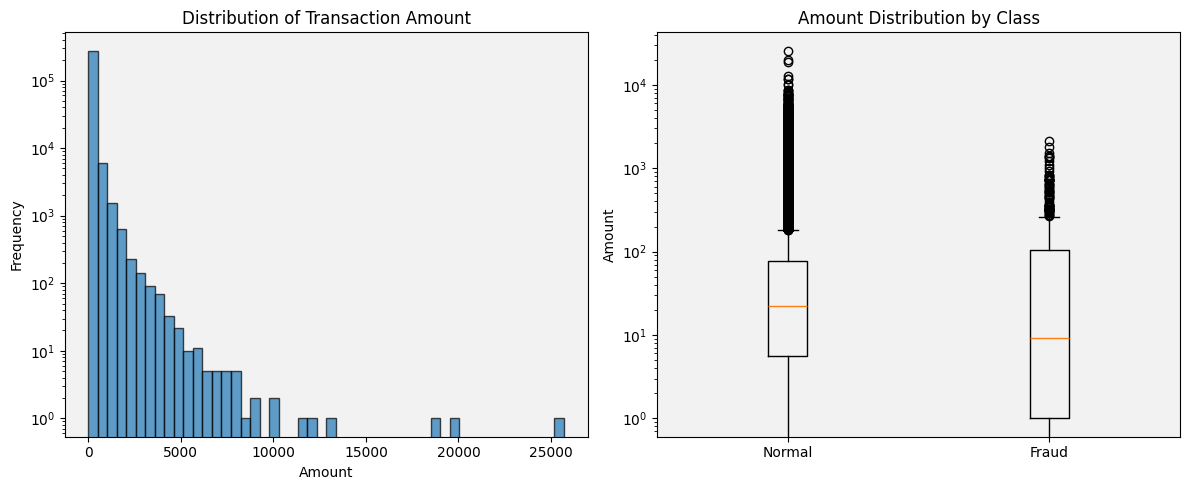


D. Correlation with target (Class):
Top 10 features with highest correlation to Class:
   Feature  Correlation_with_Class
17     V17                0.326481
14     V14                0.302544
12     V12                0.260593
10     V10                0.216883
16     V16                0.196539
3       V3                0.192961
7       V7                0.187257
11     V11                0.154876
4       V4                0.133447
18     V18                0.111485


In [33]:
print("\n=== DATA PREPROCESSING ===")

# A. Cek missing values
print("A. Checking missing values:")
print(f"Missing values: {X.isnull().sum().sum()}")

# B. Cek data types
print("\nB. Data types:")
print(X.dtypes.value_counts())

# C. Statistical summary
print("\nC. Statistical summary (first 5 features):")
print(X[['Time', 'Amount', 'V1', 'V2', 'V3']].describe())

# D. Visualisasi distribusi Amount
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(X['Amount'], bins=50, edgecolor='black', alpha=0.7)
plt.title('Distribution of Transaction Amount')
plt.xlabel('Amount')
plt.ylabel('Frequency')
plt.yscale('log')  # Log scale karena sangat skewed

plt.subplot(1, 2, 2)
fraud_amount = X[y == 1]['Amount']
normal_amount = X[y == 0]['Amount']

plt.boxplot([normal_amount, fraud_amount], labels=['Normal', 'Fraud'])
plt.title('Amount Distribution by Class')
plt.ylabel('Amount')
plt.yscale('log')

plt.tight_layout()
plt.show()

# E. Korelasi dengan target
print("\nD. Correlation with target (Class):")
correlations = []
for col in X.columns:
    corr = df[[col, 'Class']].corr().iloc[0, 1]
    correlations.append((col, abs(corr)))

correlations_df = pd.DataFrame(correlations, columns=['Feature', 'Correlation_with_Class'])
correlations_df = correlations_df.sort_values('Correlation_with_Class', ascending=False)

print("Top 10 features with highest correlation to Class:")
print(correlations_df.head(10).to_string())

In [34]:
print("\n=== RULE-BASED FEATURE ENGINEERING ===")
print("Creating rule-based features according to journal...")

def create_rule_based_features_transaction(df):
    """
    Create rule-based features for transaction fraud detection
    Based on: transaction amount, frequency, time patterns, etc.
    """
    df_features = df.copy()
    
    print("Creating 6 rule-based features...")
    
    # 1. HIGH_AMOUNT_TRANSACTION (Rule 1)
    # Transactions above 95th percentile are suspicious
    high_amount_threshold = df_features['Amount'].quantile(0.95)
    df_features['HIGH_AMOUNT'] = (df_features['Amount'] > high_amount_threshold).astype(int)
    print(f"  Rule 1 - HIGH_AMOUNT (> {high_amount_threshold:.2f}): {df_features['HIGH_AMOUNT'].sum():,} transactions")
    
    # 2. ABNORMAL_TIME (Rule 2)
    # Transactions outside normal hours (midnight - 6 AM)
    # Convert time to hours (assuming 1 second = 1 unit, 3600 seconds = 1 hour)
    df_features['Hour'] = (df_features['Time'] % (24 * 3600)) / 3600
    df_features['ABNORMAL_TIME'] = ((df_features['Hour'] >= 0) & (df_features['Hour'] <= 6)).astype(int)
    print(f"  Rule 2 - ABNORMAL_TIME (12 AM - 6 AM): {df_features['ABNORMAL_TIME'].sum():,} transactions")
    
    # 3. MICRO_TRANSACTION (Rule 3)
    # Very small transactions can be suspicious
    micro_threshold = df_features['Amount'].quantile(0.01)
    df_features['MICRO_TRANSACTION'] = (df_features['Amount'] < micro_threshold).astype(int)
    print(f"  Rule 3 - MICRO_TRANSACTION (< {micro_threshold:.4f}): {df_features['MICRO_TRANSACTION'].sum():,} transactions")
    
    # 4. FREQUENT_AMOUNT (Rule 4)
    # Same amount used frequently
    amount_counts = df_features['Amount'].round(2).value_counts()
    df_features['FREQUENT_AMOUNT'] = df_features['Amount'].round(2).map(amount_counts)
    df_features['FREQUENT_AMOUNT'] = (df_features['FREQUENT_AMOUNT'] > 5).astype(int)
    print(f"  Rule 4 - FREQUENT_AMOUNT (same amount > 5 times): {df_features['FREQUENT_AMOUNT'].sum():,} transactions")
    
    # 5. EXTREME_PCA_VALUE (Rule 5)
    # Extreme values in PCA components (beyond 3 standard deviations)
    v_columns = [col for col in df_features.columns if col.startswith('V')]
    extreme_flags = []
    
    for v_col in v_columns[:5]:  # Check first 5 PCA components
        mean_val = df_features[v_col].mean()
        std_val = df_features[v_col].std()
        extreme_flag = ((df_features[v_col] > mean_val + 3*std_val) | 
                        (df_features[v_col] < mean_val - 3*std_val)).astype(int)
        extreme_flags.append(extreme_flag)
    
    df_features['EXTREME_PCA'] = pd.DataFrame(extreme_flags).T.sum(axis=1)
    df_features['EXTREME_PCA'] = (df_features['EXTREME_PCA'] > 0).astype(int)
    print(f"  Rule 5 - EXTREME_PCA (extreme in any of first 5 PCA): {df_features['EXTREME_PCA'].sum():,} transactions")
    
    # 6. HIGH_AMOUNT_ABNORMAL_TIME (Rule 6 - Combination)
    df_features['HIGH_AMOUNT_ABNORMAL_TIME'] = (df_features['HIGH_AMOUNT'] & df_features['ABNORMAL_TIME']).astype(int)
    print(f"  Rule 6 - HIGH_AMOUNT + ABNORMAL_TIME: {df_features['HIGH_AMOUNT_ABNORMAL_TIME'].sum():,} transactions")
    
    # Drop helper columns
    df_features = df_features.drop(['Hour'], axis=1)
    
    # Get rule-based columns
    rule_cols = [col for col in df_features.columns if col in ['HIGH_AMOUNT', 'ABNORMAL_TIME', 
                                                                'MICRO_TRANSACTION', 'FREQUENT_AMOUNT',
                                                                'EXTREME_PCA', 'HIGH_AMOUNT_ABNORMAL_TIME']]
    
    print(f"\nCreated {len(rule_cols)} rule-based features:")
    for rule in rule_cols:
        fraud_ratio = df_features.loc[y == 1, rule].mean() * 100
        normal_ratio = df_features.loc[y == 0, rule].mean() * 100
        print(f"  {rule:25s}: Fraud={fraud_ratio:.2f}%, Normal={normal_ratio:.2f}%")
    
    return df_features, rule_cols

# Apply rule-based feature engineering
X_with_rules, rule_cols = create_rule_based_features_transaction(X)

# Gabungkan dengan original features
X_enhanced = pd.concat([X, X_with_rules[rule_cols]], axis=1)
print(f"\nEnhanced dataset shape: {X_enhanced.shape}")
print(f"Original features: {X.shape[1]}")
print(f"Rule-based features: {len(rule_cols)}")
print(f"Total features: {X_enhanced.shape[1]}")


=== RULE-BASED FEATURE ENGINEERING ===
Creating rule-based features according to journal...
Creating 6 rule-based features...
  Rule 1 - HIGH_AMOUNT (> 365.00): 14,232 transactions
  Rule 2 - ABNORMAL_TIME (12 AM - 6 AM): 23,935 transactions
  Rule 3 - MICRO_TRANSACTION (< 0.1200): 2,769 transactions
  Rule 4 - FREQUENT_AMOUNT (same amount > 5 times): 238,520 transactions
  Rule 5 - EXTREME_PCA (extreme in any of first 5 PCA): 9,409 transactions
  Rule 6 - HIGH_AMOUNT + ABNORMAL_TIME: 746 transactions

Created 6 rule-based features:
  HIGH_AMOUNT              : Fraud=8.74%, Normal=4.99%
  ABNORMAL_TIME            : Fraud=25.20%, Normal=8.37%
  MICRO_TRANSACTION        : Fraud=6.50%, Normal=0.96%
  FREQUENT_AMOUNT          : Fraud=74.59%, Normal=83.76%
  EXTREME_PCA              : Fraud=63.82%, Normal=3.20%
  HIGH_AMOUNT_ABNORMAL_TIME: Fraud=1.63%, Normal=0.26%

Enhanced dataset shape: (284807, 36)
Original features: 30
Rule-based features: 6
Total features: 36



=== FEATURE SCALING ===
Numerical features to scale: 30
Rule-based features (binary): 6

Scaling completed!
Original Amount - Mean: 88.35, Std: 250.12
Scaled Amount - Mean: 0.9271, Std: 3.4950


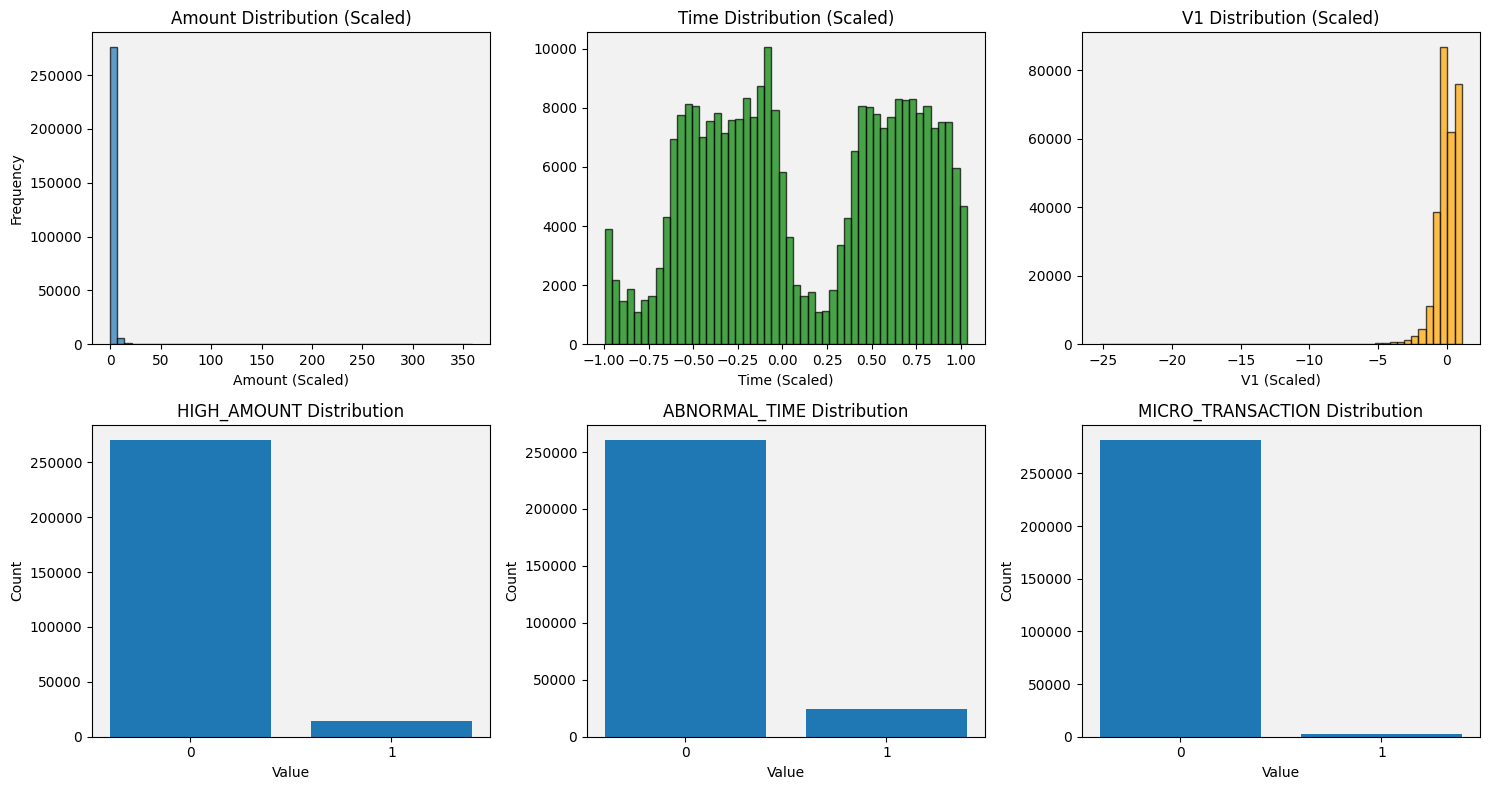

In [35]:
print("\n=== FEATURE SCALING ===")

# Pisahkan numerical features
numerical_cols = ['Time', 'Amount'] + [f'V{i}' for i in range(1, 29)]
rule_based_cols = rule_cols

print(f"Numerical features to scale: {len(numerical_cols)}")
print(f"Rule-based features (binary): {len(rule_based_cols)}")

# Gunakan RobustScaler untuk numerical features (lebih robust terhadap outliers)
from sklearn.preprocessing import RobustScaler

robust_scaler = RobustScaler()
X_scaled = X_enhanced.copy()

# Scale numerical features
X_scaled[numerical_cols] = robust_scaler.fit_transform(X_enhanced[numerical_cols])

print("\nScaling completed!")
print(f"Original Amount - Mean: {X['Amount'].mean():.2f}, Std: {X['Amount'].std():.2f}")
print(f"Scaled Amount - Mean: {X_scaled['Amount'].mean():.4f}, Std: {X_scaled['Amount'].std():.4f}")

# Cek distribusi setelah scaling
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Plot 1: Amount distribution
axes[0, 0].hist(X_scaled['Amount'], bins=50, alpha=0.7, edgecolor='black')
axes[0, 0].set_title('Amount Distribution (Scaled)')
axes[0, 0].set_xlabel('Amount (Scaled)')
axes[0, 0].set_ylabel('Frequency')

# Plot 2: Time distribution
axes[0, 1].hist(X_scaled['Time'], bins=50, alpha=0.7, edgecolor='black', color='green')
axes[0, 1].set_title('Time Distribution (Scaled)')
axes[0, 1].set_xlabel('Time (Scaled)')

# Plot 3: V1 distribution
axes[0, 2].hist(X_scaled['V1'], bins=50, alpha=0.7, edgecolor='black', color='orange')
axes[0, 2].set_title('V1 Distribution (Scaled)')
axes[0, 2].set_xlabel('V1 (Scaled)')

# Plot 4: Rule-based features distribution
for i, rule in enumerate(rule_cols[:3]):
    axes[1, i].bar(['0', '1'], X_scaled[rule].value_counts().sort_index().values)
    axes[1, i].set_title(f'{rule} Distribution')
    axes[1, i].set_xlabel('Value')
    axes[1, i].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [36]:
print("\n=== FEATURE IMPORTANCE ANALYSIS (BEFORE AUTOENCODER) ===")
print("Using Random Forest for initial feature importance...")

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Split data untuk feature importance analysis
X_train, X_test_fi, y_train, y_test_fi = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test_fi.shape}")
print(f"Fraud ratio in train: {y_train.mean():.4f}")
print(f"Fraud ratio in test: {y_test_fi.mean():.4f}")

# Train Random Forest untuk feature importance
print("\nTraining Random Forest Classifier...")
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Get feature importance
feature_importance = rf_model.feature_importances_

# Create importance dataframe
importance_df = pd.DataFrame({
    'Feature': X_scaled.columns.tolist(),
    'Importance': feature_importance,
    'Type': ['Original' if col not in rule_cols else 'Rule-Based' for col in X_scaled.columns]
})

# Sort by importance
importance_df = importance_df.sort_values('Importance', ascending=False).reset_index(drop=True)

print("\n=== TOP 20 MOST IMPORTANT FEATURES ===")
print(importance_df.head(20).to_string())

print("\n=== RULE-BASED FEATURES RANKING ===")
rule_importance = importance_df[importance_df['Type'] == 'Rule-Based']
print(rule_importance.to_string())
print(f"\nAverage importance of rule-based features: {rule_importance['Importance'].mean():.4f}")
print(f"Best rule-based feature: {rule_importance.iloc[0]['Feature']} ({rule_importance.iloc[0]['Importance']:.4f})")


=== FEATURE IMPORTANCE ANALYSIS (BEFORE AUTOENCODER) ===
Using Random Forest for initial feature importance...
Training set: (199364, 36)
Test set: (85443, 36)
Fraud ratio in train: 0.0017
Fraud ratio in test: 0.0017

Training Random Forest Classifier...

=== TOP 20 MOST IMPORTANT FEATURES ===
        Feature  Importance        Type
0           V14    0.246206    Original
1           V10    0.103168    Original
2            V4    0.087147    Original
3           V12    0.079065    Original
4           V11    0.067703    Original
5           V17    0.061519    Original
6            V3    0.059043    Original
7            V7    0.048661    Original
8           V16    0.040176    Original
9   EXTREME_PCA    0.030828  Rule-Based
10           V9    0.021896    Original
11          V18    0.021035    Original
12           V2    0.012971    Original
13          V19    0.010869    Original
14          V21    0.009270    Original
15          V27    0.008766    Original
16          V20    0.008


=== VISUALIZING FEATURE IMPORTANCE ===


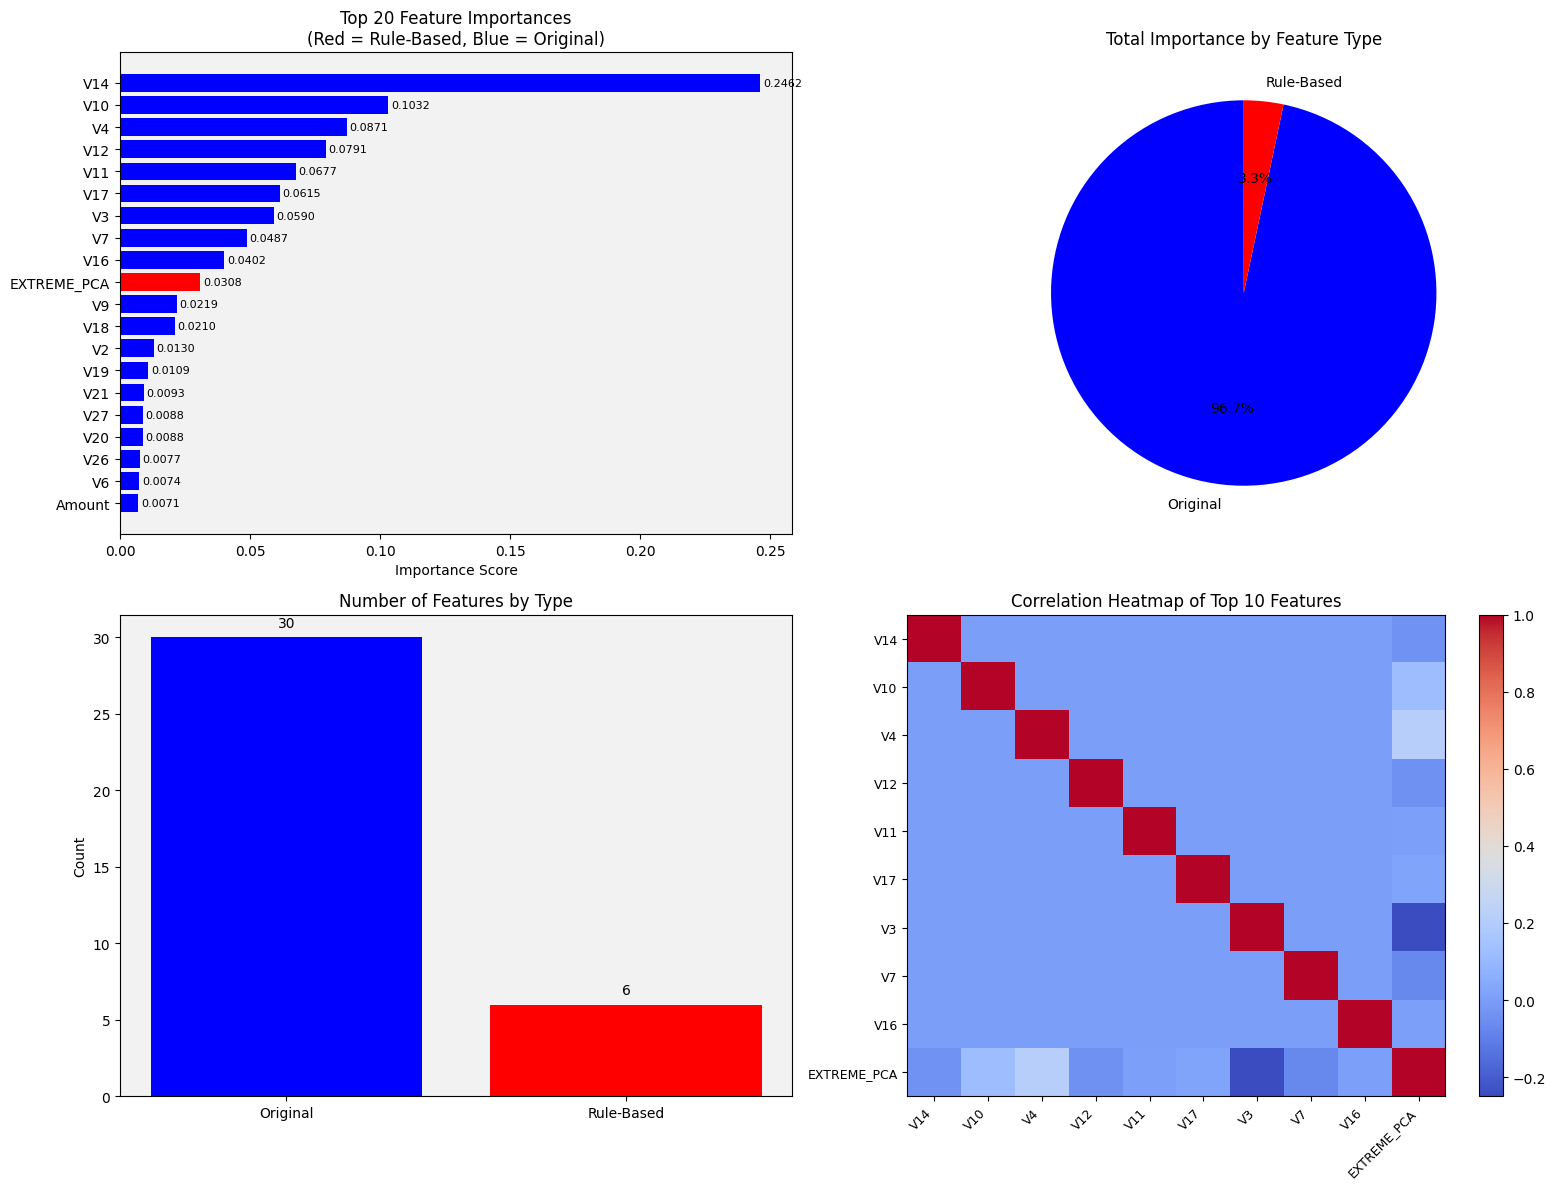

In [37]:
print("\n=== VISUALIZING FEATURE IMPORTANCE ===")

# Create visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Top 20 Features Bar Chart
top_n = 20
top_features = importance_df.head(top_n)

colors = ['red' if ft in rule_cols else 'blue' for ft in top_features['Feature']]
axes[0, 0].barh(range(top_n), top_features['Importance'], color=colors)
axes[0, 0].set_yticks(range(top_n))
axes[0, 0].set_yticklabels(top_features['Feature'])
axes[0, 0].set_xlabel('Importance Score')
axes[0, 0].set_title(f'Top {top_n} Feature Importances\n(Red = Rule-Based, Blue = Original)')
axes[0, 0].invert_yaxis()

# Add values
for i, (idx, row) in enumerate(top_features.iterrows()):
    axes[0, 0].text(row['Importance'] + 0.001, i, f'{row["Importance"]:.4f}', 
                    va='center', fontsize=8)

# 2. Feature Type Comparison
type_importance = importance_df.groupby('Type')['Importance'].sum()
colors_type = ['blue', 'red']
axes[0, 1].pie(type_importance.values, labels=type_importance.index, 
               autopct='%1.1f%%', colors=colors_type, startangle=90)
axes[0, 1].set_title('Total Importance by Feature Type')

# 3. Original vs Rule-Based Feature Count
type_counts = importance_df['Type'].value_counts()
axes[1, 0].bar(type_counts.index, type_counts.values, color=['blue', 'red'])
axes[1, 0].set_title('Number of Features by Type')
axes[1, 0].set_ylabel('Count')
for i, v in enumerate(type_counts.values):
    axes[1, 0].text(i, v + 0.5, str(v), ha='center', va='bottom')

# 4. Correlation Heatmap (Top 10 features)
top_10_features = importance_df.head(10)['Feature'].tolist()
correlation_matrix = X_scaled[top_10_features].corr()

im = axes[1, 1].imshow(correlation_matrix, cmap='coolwarm', aspect='auto')
axes[1, 1].set_xticks(range(len(top_10_features)))
axes[1, 1].set_yticks(range(len(top_10_features)))
axes[1, 1].set_xticklabels(top_10_features, rotation=45, ha='right', fontsize=9)
axes[1, 1].set_yticklabels(top_10_features, fontsize=9)
axes[1, 1].set_title('Correlation Heatmap of Top 10 Features')
plt.colorbar(im, ax=axes[1, 1])

plt.tight_layout()
plt.show()

In [38]:
print("\n=== PREPARING DATA FOR AUTOENCODER ===")

# Sesuai jurnal: Autoencoder hanya dilatih pada data NORMAL
print("According to journal: Autoencoder trained ONLY on NORMAL transactions")

# Pisahkan normal dan fraud
X_normal = X_scaled[y == 0]
X_fraud = X_scaled[y == 1]
y_normal = y[y == 0]
y_fraud = y[y == 1]

print(f"\nNormal transactions: {len(X_normal):,}")
print(f"Fraud transactions: {len(X_fraud):,}")

# Split normal data: 70% training, 30% testing
from sklearn.model_selection import train_test_split

X_train_normal, X_temp_normal = train_test_split(
    X_normal, test_size=0.3, random_state=42
)

# Test set: 30% normal + semua fraud
X_test_normal = X_temp_normal
X_test = pd.concat([X_test_normal, X_fraud], axis=0, ignore_index=True)
y_test = pd.concat([pd.Series([0]*len(X_test_normal)), y_fraud.reset_index(drop=True)], 
                   axis=0, ignore_index=True)

print(f"\nTraining set (normal only): {len(X_train_normal):,}")
print(f"Test set - Normal: {len(X_test_normal):,}")
print(f"Test set - Fraud: {len(X_fraud):,}")
print(f"Test set - Total: {len(X_test):,}")
print(f"Fraud percentage in test set: {y_test.mean()*100:.4f}%")

# Convert to numpy arrays untuk AutoEncoder
X_ae_train = X_train_normal.values.astype(np.float32)
X_ae_test = X_test.values.astype(np.float32)
y_ae_test = y_test.values

print(f"\nAutoEncoder training data shape: {X_ae_train.shape}")
print(f"AutoEncoder test data shape: {X_ae_test.shape}")


=== PREPARING DATA FOR AUTOENCODER ===
According to journal: Autoencoder trained ONLY on NORMAL transactions

Normal transactions: 284,315
Fraud transactions: 492

Training set (normal only): 199,020
Test set - Normal: 85,295
Test set - Fraud: 492
Test set - Total: 85,787
Fraud percentage in test set: 0.5735%

AutoEncoder training data shape: (199020, 36)
AutoEncoder test data shape: (85787, 36)


In [39]:
print("\n=== SAVING PREPROCESSED DATA ===")

import joblib
import os

# Buat directory jika belum ada
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'
os.makedirs(output_dir, exist_ok=True)

# Save semua data yang diperlukan
preprocessed_data = {
    # Raw data
    'X_raw': X.values,
    'y_raw': y.values,
    
    # Enhanced data
    'X_enhanced': X_scaled.values,
    'X_enhanced_columns': X_scaled.columns.tolist(),
    
    # AutoEncoder data
    'X_ae_train': X_ae_train,
    'X_ae_test': X_ae_test,
    'y_ae_test': y_ae_test,
    
    # Feature information
    'feature_names': X_scaled.columns.tolist(),
    'rule_based_features': rule_cols,
    'numerical_features': numerical_cols,
    
    # Feature importance
    'feature_importance_df': importance_df,
    
    # Scaler
    'robust_scaler': robust_scaler,
    
    # Metadata
    'dataset_info': {
        'total_samples': len(df),
        'normal_samples': len(X_normal),
        'fraud_samples': len(X_fraud),
        'fraud_percentage': (len(X_fraud) / len(df)) * 100,
        'original_features': X.shape[1],
        'enhanced_features': X_scaled.shape[1],
        'rule_based_count': len(rule_cols)
    }
}

# Save ke file
joblib.dump(preprocessed_data, os.path.join(output_dir, 'creditcard_ae_preprocessed.pkl'))

print(f"Preprocessed data saved to: {output_dir}creditcard_ae_preprocessed.pkl")

print("\n=== DATASET INFORMATION ===")
info = preprocessed_data['dataset_info']
print(f"Total samples: {info['total_samples']:,}")
print(f"Normal transactions: {info['normal_samples']:,}")
print(f"Fraud transactions: {info['fraud_samples']:,}")
print(f"Fraud percentage: {info['fraud_percentage']:.4f}%")
print(f"\nOriginal features: {info['original_features']}")
print(f"Enhanced features: {info['enhanced_features']}")
print(f"Rule-based features added: {info['rule_based_count']}")
print(f"\nAutoEncoder training samples: {X_ae_train.shape[0]:,}")
print(f"AutoEncoder test samples: {X_ae_test.shape[0]:,}")


=== SAVING PREPROCESSED DATA ===
Preprocessed data saved to: /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/creditcard_ae_preprocessed.pkl

=== DATASET INFORMATION ===
Total samples: 284,807
Normal transactions: 284,315
Fraud transactions: 492
Fraud percentage: 0.1727%

Original features: 30
Enhanced features: 36
Rule-based features added: 6

AutoEncoder training samples: 199,020
AutoEncoder test samples: 85,787


In [40]:
print("\n" + "="*60)
print("DATA PREPROCESSING & FEATURE IMPORTANCE COMPLETED!")
print("="*60)

print("\n=== SUMMARY ===")
print("✅ 1. Dataset loaded and explored")
print("✅ 2. Rule-based feature engineering implemented (6 rules)")
print("✅ 3. Feature scaling applied (RobustScaler)")
print("✅ 4. Feature importance analyzed using Random Forest")
print("✅ 5. Data prepared for AutoEncoder (normal transactions only)")
print("✅ 6. All data saved for next steps")

print("\n=== KEY FINDINGS ===")
print(f"1. Most important original feature: {importance_df.iloc[0]['Feature']}")
print(f"2. Most important rule-based feature: {rule_importance.iloc[0]['Feature']}")
print(f"3. Rule-based features contribute: {type_importance.get('Rule-Based', 0)*100:.1f}% of total importance")
print(f"4. Number of features for AutoEncoder: {X_ae_train.shape[1]}")

print("\n=== NEXT STEPS (Sesuai Jurnal) ===")
print("1. Train AutoEncoder on normal transactions only")
print("2. Extract μ features [A, B, C] from AutoEncoder:")
print("   - A: Compressed representation")
print("   - B: Euclidean distance (reconstruction error)")
print("   - C: Similarity degree")
print("3. Combine Ω (original + rule-based) + μ (AE) features")
print("4. Train Extended Isolation Forest on combined features")
print("5. Implement two-step detection: AE filter → EIF analysis")
print("6. Evaluate AE-EIF hybrid model performance")

print("\nData is ready for AutoEncoder training!")


DATA PREPROCESSING & FEATURE IMPORTANCE COMPLETED!

=== SUMMARY ===
✅ 1. Dataset loaded and explored
✅ 2. Rule-based feature engineering implemented (6 rules)
✅ 3. Feature scaling applied (RobustScaler)
✅ 4. Feature importance analyzed using Random Forest
✅ 5. Data prepared for AutoEncoder (normal transactions only)
✅ 6. All data saved for next steps

=== KEY FINDINGS ===
1. Most important original feature: V14
2. Most important rule-based feature: EXTREME_PCA
3. Rule-based features contribute: 3.3% of total importance
4. Number of features for AutoEncoder: 36

=== NEXT STEPS (Sesuai Jurnal) ===
1. Train AutoEncoder on normal transactions only
2. Extract μ features [A, B, C] from AutoEncoder:
   - A: Compressed representation
   - B: Euclidean distance (reconstruction error)
   - C: Similarity degree
3. Combine Ω (original + rule-based) + μ (AE) features
4. Train Extended Isolation Forest on combined features
5. Implement two-step detection: AE filter → EIF analysis
6. Evaluate AE-EIF

In [42]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 259.5/259.5 MB 1.7 MB/s  0:02:14m0:00:0100:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 2.5 MB/s  0:00:04m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 2.6 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 1.9 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 2.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.5/26.5 MB 2.2 MB/s  0:00:12m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 2.1 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29/29 [tensorflow]9 [tensorflow]]alizer]rver]


In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

print("=== LOADING PREPROCESSED DATA ===")

# Load preprocessed data
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'
preprocessed_data = joblib.load(os.path.join(output_dir, 'creditcard_ae_preprocessed.pkl'))

# Extract data
X_ae_train = preprocessed_data['X_ae_train']
X_ae_test = preprocessed_data['X_ae_test']
y_ae_test = preprocessed_data['y_ae_test']
feature_names = preprocessed_data['feature_names']
rule_cols = preprocessed_data['rule_based_features']

print(f"X_ae_train shape: {X_ae_train.shape}")
print(f"X_ae_test shape: {X_ae_test.shape}")
print(f"Number of features: {X_ae_train.shape[1]}")
print(f"Rule-based features: {rule_cols}")
print(f"Training samples (normal only): {X_ae_train.shape[0]:,}")
print(f"Test samples: {X_ae_test.shape[0]:,} (Fraud: {y_ae_test.sum():,})")

2025-12-22 20:27:59.716098: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


=== LOADING PREPROCESSED DATA ===
X_ae_train shape: (199020, 36)
X_ae_test shape: (85787, 36)
Number of features: 36
Rule-based features: ['HIGH_AMOUNT', 'ABNORMAL_TIME', 'MICRO_TRANSACTION', 'FREQUENT_AMOUNT', 'EXTREME_PCA', 'HIGH_AMOUNT_ABNORMAL_TIME']
Training samples (normal only): 199,020
Test samples: 85,787 (Fraud: 492)


In [44]:
print("\n" + "="*60)
print("AUTOENCODER IMPLEMENTATION ACCORDING TO JOURNAL")
print("="*60)

print("\n=== AUTOENCODER ARCHITECTURE (Section 6.1 & 6.3.2) ===")
print("According to journal:")
print("1. Input layer: n features (in our case: 36 features)")
print("2. Hidden layers: 14 → 7 → 14 nodes")
print("3. Output layer: n features (reconstruction)")
print("4. Activation: ReLU")
print("5. Training: Only on normal transactions")
print("6. Output: μ features [A, B, C]")

# Architecture parameters
input_dim = X_ae_train.shape[1]  # 36 features
encoding_dim1 = 14  # First hidden layer
encoding_dim2 = 7   # Bottleneck layer
encoding_dim3 = 14  # Third hidden layer

print(f"\nAutoEncoder Configuration:")
print(f"Input dimension: {input_dim}")
print(f"Architecture: Input({input_dim}) → Dense({encoding_dim1}) → Dense({encoding_dim2})")
print(f"               → Dense({encoding_dim3}) → Output({input_dim})")


AUTOENCODER IMPLEMENTATION ACCORDING TO JOURNAL

=== AUTOENCODER ARCHITECTURE (Section 6.1 & 6.3.2) ===
According to journal:
1. Input layer: n features (in our case: 36 features)
2. Hidden layers: 14 → 7 → 14 nodes
3. Output layer: n features (reconstruction)
4. Activation: ReLU
5. Training: Only on normal transactions
6. Output: μ features [A, B, C]

AutoEncoder Configuration:
Input dimension: 36
Architecture: Input(36) → Dense(14) → Dense(7)
               → Dense(14) → Output(36)


In [45]:
print("\n=== BUILDING AUTOENCODER MODEL ===")

# Set random seeds for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Build Encoder
input_layer = Input(shape=(input_dim,), name='input')

# Encoder layers sesuai jurnal
encoded1 = Dense(encoding_dim1, activation='relu', name='encoder1')(input_layer)
encoded1_bn = BatchNormalization(name='bn1')(encoded1)

encoded2 = Dense(encoding_dim2, activation='relu', name='encoder2')(encoded1_bn)
encoded2_bn = BatchNormalization(name='bn2')(encoded2)  # Bottleneck layer

encoded3 = Dense(encoding_dim3, activation='relu', name='encoder3')(encoded2_bn)
encoded3_bn = BatchNormalization(name='bn3')(encoded3)

# Decoder layers
decoded1 = Dense(encoding_dim2, activation='relu', name='decoder1')(encoded3_bn)
decoded1_bn = BatchNormalization(name='bn4')(decoded1)

decoded2 = Dense(encoding_dim1, activation='relu', name='decoder2')(decoded1_bn)
decoded2_bn = BatchNormalization(name='bn5')(decoded2)

output_layer = Dense(input_dim, activation='linear', name='output')(decoded2_bn)

# Create AutoEncoder model
autoencoder = Model(inputs=input_layer, outputs=output_layer, name='AutoEncoder')

# Create separate Encoder model (untuk ekstraksi fitur μ)
encoder = Model(inputs=input_layer, outputs=encoded2_bn, name='Encoder')  # Output dari bottleneck

print("\nAutoEncoder Summary:")
autoencoder.summary()

print(f"\nEncoder (for μ features extraction) summary:")
encoder.summary()


=== BUILDING AUTOENCODER MODEL ===

AutoEncoder Summary:


Model: "AutoEncoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 36)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder1 (Dense)                │ (None, 14)             │           518 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 14)             │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder2 (Dense)                │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 7)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder3 (Dense)                │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 14)             │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder1 (Dense)                │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 7)              │            28 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder2 (Dense)                │ (None, 14)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn5 (BatchNormalization)        │ (None, 14)             │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 36)             │           540 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,716 (6.70 KB)

 Trainable params: 1,604 (6.27 KB)

...

Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 36)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder1 (Dense)                │ (None, 14)             │           518 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 14)             │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder2 (Dense)                │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 7)              │            28 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 707 (2.76 KB)

 Trainable params: 665 (2.60 KB)

 Non-trainable params: 42 (168.00 B)

In [46]:
print("\n=== COMPILING AND TRAINING AUTOENCODER ===")

# Compile model
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',  # Mean Squared Error untuk reconstruction
    metrics=['mae', 'cosine_similarity']  # Additional metrics
)

# Callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=os.path.join(output_dir, 'autoencoder_best.h5'),
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print(f"Training AutoEncoder for 100 epochs...")
print(f"Batch size: 32")
print(f"Validation split: 0.2")

# Train AutoEncoder
history = autoencoder.fit(
    X_ae_train, X_ae_train,  # Autoencoder learns to reconstruct its input
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.2,
    callbacks=callbacks,
    verbose=1
)

print("\nAutoEncoder training completed!")


=== COMPILING AND TRAINING AUTOENCODER ===
Training AutoEncoder for 100 epochs...
Batch size: 32
Validation split: 0.2
Epoch 1/100
4973/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - cosine_similarity: 0.3736 - loss: 1.4193 - mae: 0.5989
Epoch 1: val_loss improved from None to 0.78004, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 111s 19ms/step - cosine_similarity: 0.4655 - loss: 1.1799 - mae: 0.5591 - val_cosine_similarity: 0.5691 - val_loss: 0.7800 - val_mae: 0.4969 - learning_rate: 0.0010
Epoch 2/100
4973/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - cosine_similarity: 0.5309 - loss: 1.0243 - mae: 0.5295
Epoch 2: val_loss improved from 0.78004 to 0.71622, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 99s 20ms/step - cosine_similarity: 0.5328 - loss: 0.9533 - mae: 0.5261 - val_cosine_similarity: 0.5860 - val_loss: 0.7162 - val_mae: 0.4816 - learning_rate: 0.0010
Epoch 3/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - cosine_similarity: 0.5349 - loss: 0.9146 - mae: 0.5223
Epoch 3: val_loss improved from 0.71622 to 0.67399, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 39s 8ms/step - cosine_similarity: 0.5360 - loss: 0.8523 - mae: 0.5194 - val_cosine_similarity: 0.5852 - val_loss: 0.6740 - val_mae: 0.4775 - learning_rate: 0.0010
Epoch 4/100
4969/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - cosine_similarity: 0.5438 - loss: 0.8144 - mae: 0.5116
Epoch 4: val_loss improved from 0.67399 to 0.62284, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 38s 8ms/step - cosine_similarity: 0.5498 - loss: 0.7469 - mae: 0.5052 - val_cosine_similarity: 0.5721 - val_loss: 0.6228 - val_mae: 0.4801 - learning_rate: 0.0010
Epoch 5/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - cosine_similarity: 0.5694 - loss: 0.6962 - mae: 0.4911
Epoch 5: val_loss improved from 0.62284 to 0.57636, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


...

4976/4976 ━━━━━━━━━━━━━━━━━━━━ 107s 22ms/step - cosine_similarity: 0.6036 - loss: 0.4669 - mae: 0.4527 - val_cosine_similarity: 0.6695 - val_loss: 0.4290 - val_mae: 0.3962 - learning_rate: 1.5625e-05
Epoch 90/100
4975/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - cosine_similarity: 0.6041 - loss: 0.4753 - mae: 0.4532
Epoch 90: val_loss improved from 0.42900 to 0.42883, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 56s 11ms/step - cosine_similarity: 0.6036 - loss: 0.4668 - mae: 0.4527 - val_cosine_similarity: 0.6695 - val_loss: 0.4288 - val_mae: 0.3961 - learning_rate: 1.5625e-05
Epoch 91/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - cosine_similarity: 0.6041 - loss: 0.4752 - mae: 0.4532
Epoch 91: val_loss did not improve from 0.42883
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 211s 42ms/step - cosine_similarity: 0.6036 - loss: 0.4668 - mae: 0.4527 - val_cosine_similarity: 0.6696 - val_loss: 0.4290 - val_mae: 0.3962 - learning_rate: 1.5625e-05
Epoch 92/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - cosine_similarity: 0.6042 - loss: 0.4752 - mae: 0.4532
Epoch 92: val_loss improved from 0.42883 to 0.42871, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 361s 72ms/step - cosine_similarity: 0.6036 - loss: 0.4668 - mae: 0.4527 - val_cosine_similarity: 0.6695 - val_loss: 0.4287 - val_mae: 0.3961 - learning_rate: 1.5625e-05
Epoch 93/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - cosine_similarity: 0.6042 - loss: 0.4752 - mae: 0.4532
Epoch 93: val_loss improved from 0.42871 to 0.42867, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 387s 78ms/step - cosine_similarity: 0.6036 - loss: 0.4668 - mae: 0.4527 - val_cosine_similarity: 0.6696 - val_loss: 0.4287 - val_mae: 0.3961 - learning_rate: 1.5625e-05
Epoch 94/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - cosine_similarity: 0.6042 - loss: 0.4751 - mae: 0.4532
Epoch 94: val_loss improved from 0.42867 to 0.42860, saving model to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/autoencoder_best.h5


4976/4976 ━━━━━━━━━━━━━━━━━━━━ 399s 80ms/step - cosine_similarity: 0.6036 - loss: 0.4667 - mae: 0.4527 - val_cosine_similarity: 0.6696 - val_loss: 0.4286 - val_mae: 0.3961 - learning_rate: 1.5625e-05
Epoch 95/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - cosine_similarity: 0.6042 - loss: 0.4751 - mae: 0.4532
Epoch 95: val_loss did not improve from 0.42860
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 400s 80ms/step - cosine_similarity: 0.6036 - loss: 0.4667 - mae: 0.4527 - val_cosine_similarity: 0.6695 - val_loss: 0.4290 - val_mae: 0.3962 - learning_rate: 1.5625e-05
Epoch 96/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - cosine_similarity: 0.6042 - loss: 0.4751 - mae: 0.4532
Epoch 96: val_loss did not improve from 0.42860
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 478s 96ms/step - cosine_similarity: 0.6036 - loss: 0.4667 - mae: 0.4527 - val_cosine_similarity: 0.6696 - val_loss: 0.4287 - val_mae: 0.3961 - learning_rate: 1.5625e-05
Epoch 97/100
4976/4976 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - cosine_similarity


=== TRAINING HISTORY VISUALIZATION ===


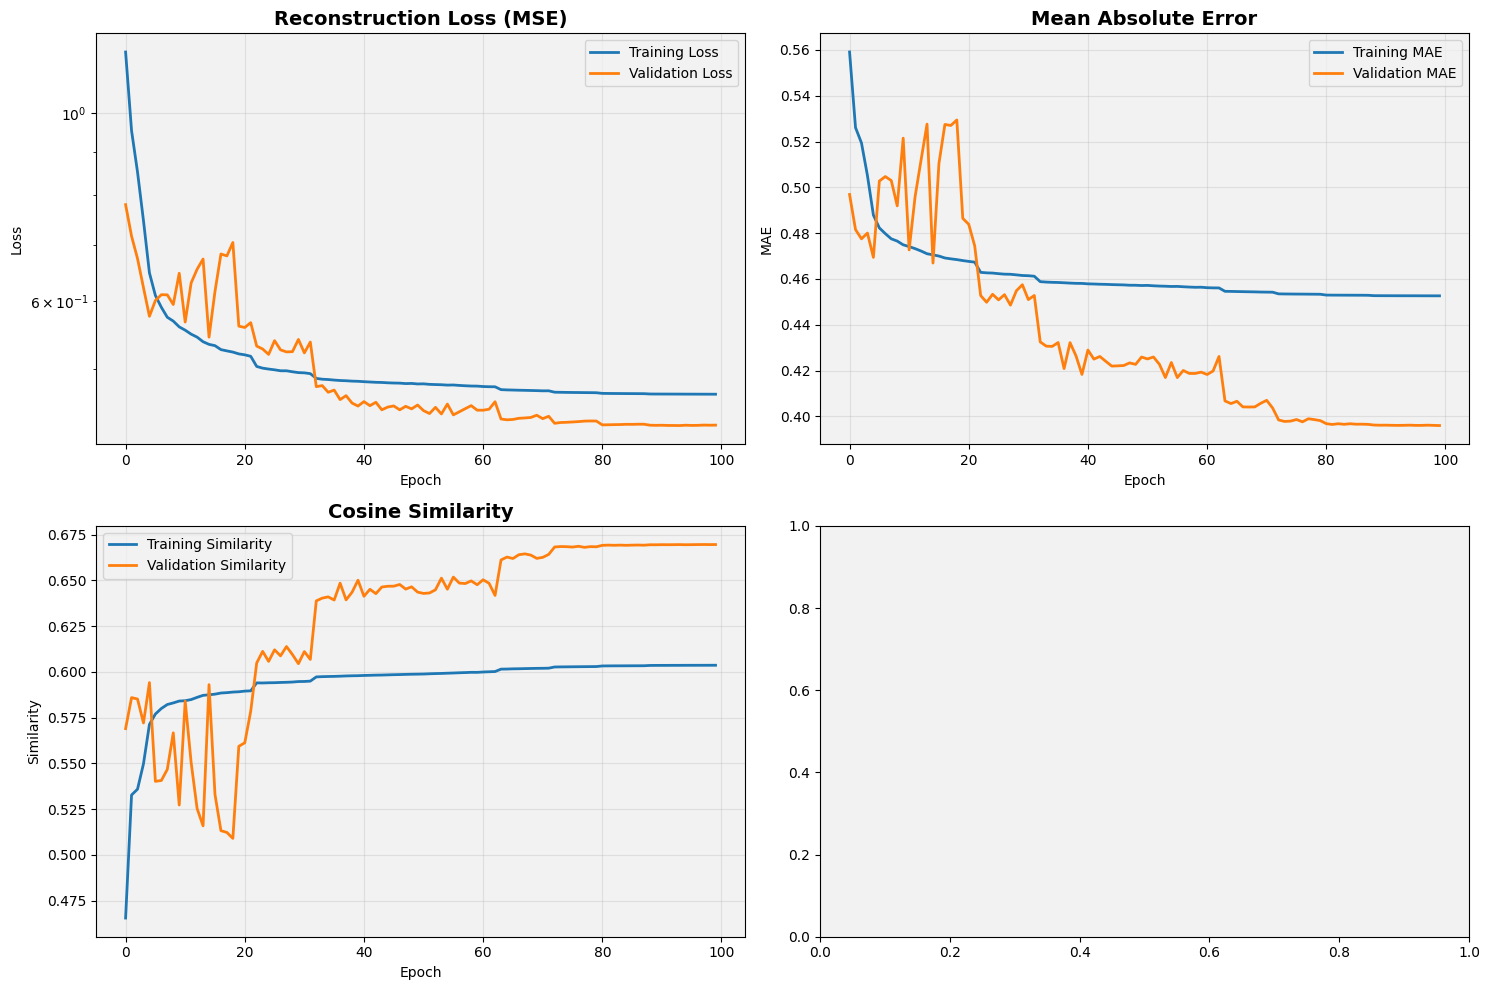


Models saved to /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/


In [47]:
print("\n=== TRAINING HISTORY VISUALIZATION ===")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Loss (MSE)
axes[0, 0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0, 0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0, 0].set_title('Reconstruction Loss (MSE)', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].set_yscale('log')

# 2. MAE
axes[0, 1].plot(history.history['mae'], label='Training MAE', linewidth=2)
axes[0, 1].plot(history.history['val_mae'], label='Validation MAE', linewidth=2)
axes[0, 1].set_title('Mean Absolute Error', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('MAE')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Cosine Similarity
axes[1, 0].plot(history.history['cosine_similarity'], label='Training Similarity', linewidth=2)
axes[1, 0].plot(history.history['val_cosine_similarity'], label='Validation Similarity', linewidth=2)
axes[1, 0].set_title('Cosine Similarity', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Similarity')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Learning Rate
if 'lr' in history.history:
    axes[1, 1].plot(history.history['lr'], linewidth=2, color='purple')
    axes[1, 1].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Learning Rate')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].set_yscale('log')

plt.tight_layout()
plt.show()

# Save final model
autoencoder.save(os.path.join(output_dir, 'autoencoder_final.h5'))
encoder.save(os.path.join(output_dir, 'encoder_final.h5'))
print(f"\nModels saved to {output_dir}")

In [11]:
# Load dataset yang sudah dikonversi
import sys
sys.path.append('../')
from utils_reboot.datasets import Dataset
import numpy as np

data_path = '/Users/apple/Desktop/Skripsi/ExIFFI/data/'

print("\n=== MENCUBA LOAD DATASET .mat ===")
try:
    dataset = Dataset('creditcard', path=data_real_path, feature_names_filepath=data_path)
    
    print(f"Berhasil! Nama dataset: {dataset.name}")
    print(f"Shape dataset: {dataset.shape}")
    print(f"Jumlah features: {dataset.shape[1]}")
    
    # Cek atribut penting
    if hasattr(dataset, 'X'):
        print(f"X shape: {dataset.X.shape}")
    if hasattr(dataset, 'y'):
        print(f"y shape: {dataset.y.shape}")
        unique, counts = np.unique(dataset.y, return_counts=True)
        print(f"Distribusi kelas: {dict(zip(unique, counts))}")
    
    # Lanjutkan dengan preprocessing
    print("\n=== PREPROCESSING ===")
    dataset.drop_duplicates()
    print(f"Setelah drop duplicates: {dataset.shape}")
    
    if dataset.shape[0] > 7500:
        dataset.downsample(max_samples=7500)
        print(f"Setelah downsample: {dataset.shape}")
    
except Exception as e:
    print(f"Error: {e}")
    print("\nMencoba cek isi file .mat...")
    
    # Debug: Cek isi file .mat
    from scipy.io import loadmat
    try:
        mat_data = loadmat(mat_path)
        print(f"Keys dalam file .mat: {list(mat_data.keys())}")
        for key, value in mat_data.items():
            if not key.startswith('__'):
                print(f"  {key}: {type(value)}, shape: {value.shape if hasattr(value, 'shape') else 'N/A'}")
    except Exception as e2:
        print(f"Error membaca .mat: {e2}")


=== MENCUBA LOAD DATASET .mat ===
Berhasil! Nama dataset: creditcard
Shape dataset: (284807, 30)
Jumlah features: 30
X shape: (284807, 30)
y shape: (284807, 1)
Distribusi kelas: {0.0: 284315, 1.0: 492}

=== PREPROCESSING ===
Setelah drop duplicates: (283726, 30)
downsampled to  7500
Setelah downsample: (7500, 30)


In [48]:
print("\n=== EXTRACTING μ FEATURES (According to Journal) ===")
print("Section 6.3.2: μ = [A, B, C] where:")
print("A: Compressed representation from AutoEncoder")
print("B: Euclidean distance between input and reconstruction")
print("C: Similarity degree between input and reconstruction")

# Get reconstructions
print("\n1. Generating reconstructions...")
reconstructions = autoencoder.predict(X_ae_test, verbose=1)

# Calculate reconstruction errors
print("\n2. Calculating reconstruction errors...")
mse_per_sample = np.mean(np.square(X_ae_test - reconstructions), axis=1)
mae_per_sample = np.mean(np.abs(X_ae_test - reconstructions), axis=1)

# Calculate μ features
print("\n3. Calculating μ features...")

# A: Compressed representation (from bottleneck layer)
print("   A: Getting compressed representation...")
A_features = encoder.predict(X_ae_test, verbose=1)  # Output from bottleneck (7 dimensions)

# B: Euclidean distance (reconstruction error)
print("   B: Calculating Euclidean distance...")
B_features = np.sqrt(np.sum(np.square(X_ae_test - reconstructions), axis=1, keepdims=True))

# C: Similarity degree (cosine similarity)
print("   C: Calculating cosine similarity...")
from sklearn.metrics.pairwise import cosine_similarity

C_features = np.array([cosine_similarity([X_ae_test[i]], [reconstructions[i]])[0][0] 
                       for i in range(len(X_ae_test))])
C_features = C_features.reshape(-1, 1)

print(f"\nμ features extracted:")
print(f"A (compressed representation): shape {A_features.shape}")
print(f"B (Euclidean distance): shape {B_features.shape}")
print(f"C (similarity degree): shape {C_features.shape}")
print(f"Total μ features per sample: {A_features.shape[1] + B_features.shape[1] + C_features.shape[1]}")

# Combine all μ features
mu_features = np.hstack([A_features, B_features, C_features])
print(f"\nCombined μ features shape: {mu_features.shape}")


=== EXTRACTING μ FEATURES (According to Journal) ===
Section 6.3.2: μ = [A, B, C] where:
A: Compressed representation from AutoEncoder
B: Euclidean distance between input and reconstruction
C: Similarity degree between input and reconstruction

1. Generating reconstructions...
2681/2681 ━━━━━━━━━━━━━━━━━━━━ 19s 7ms/step

2. Calculating reconstruction errors...

3. Calculating μ features...
   A: Getting compressed representation...
2681/2681 ━━━━━━━━━━━━━━━━━━━━ 29s 11ms/step
   B: Calculating Euclidean distance...
   C: Calculating cosine similarity...

μ features extracted:
A (compressed representation): shape (85787, 7)
B (Euclidean distance): shape (85787, 1)
C (similarity degree): shape (85787, 1)
Total μ features per sample: 9

Combined μ features shape: (85787, 9)



=== THRESHOLD DETERMINATION FOR SUSPICIOUS TRANSACTIONS ===
According to journal: Use reconstruction error to identify suspicious transactions
1. Calculating reconstruction errors on training data (normal only)...

2. Threshold determination:
   Using 95th percentile of training reconstruction errors
   Threshold value: 0.847082
   Mean training MSE: 0.418323
   Std training MSE: 5.606016


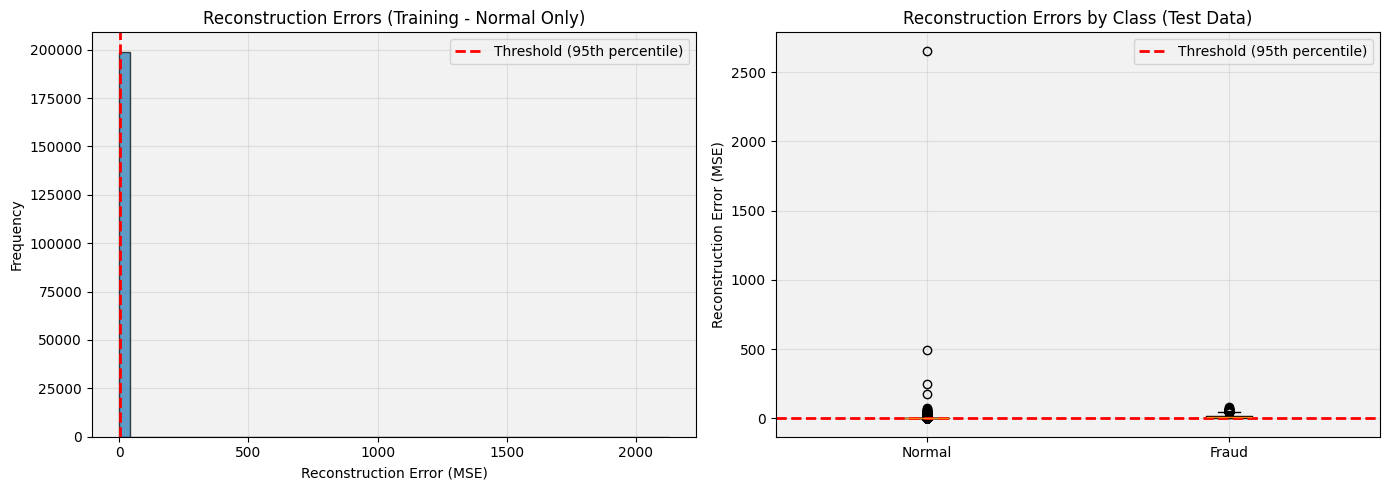


3. Suspicious transaction identification:
   Total test transactions: 85,787
   Suspicious transactions (AE): 4,725 (5.51%)
   Normal transactions (AE): 81,062 (94.49%)

   Actual fraud detected as suspicious: 436
   Actual fraud missed: 56
   False positives (normal flagged as suspicious): 4,289


In [49]:
print("\n=== THRESHOLD DETERMINATION FOR SUSPICIOUS TRANSACTIONS ===")
print("According to journal: Use reconstruction error to identify suspicious transactions")

# Calculate reconstruction errors on training data (normal only)
print("1. Calculating reconstruction errors on training data (normal only)...")
train_reconstructions = autoencoder.predict(X_ae_train, verbose=0)
train_mse = np.mean(np.square(X_ae_train - train_reconstructions), axis=1)

# Determine threshold (e.g., 95th percentile)
threshold_percentile = 95
threshold = np.percentile(train_mse, threshold_percentile)

print(f"\n2. Threshold determination:")
print(f"   Using {threshold_percentile}th percentile of training reconstruction errors")
print(f"   Threshold value: {threshold:.6f}")
print(f"   Mean training MSE: {train_mse.mean():.6f}")
print(f"   Std training MSE: {train_mse.std():.6f}")

# Visualize reconstruction errors
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of training reconstruction errors
axes[0].hist(train_mse, bins=50, alpha=0.7, edgecolor='black')
axes[0].axvline(x=threshold, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({threshold_percentile}th percentile)')
axes[0].set_title('Reconstruction Errors (Training - Normal Only)')
axes[0].set_xlabel('Reconstruction Error (MSE)')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Test data reconstruction errors by class
test_mse_normal = mse_per_sample[y_ae_test == 0]
test_mse_fraud = mse_per_sample[y_ae_test == 1]

box_data = [test_mse_normal, test_mse_fraud]
axes[1].boxplot(box_data, labels=['Normal', 'Fraud'])
axes[1].axhline(y=threshold, color='red', linestyle='--', linewidth=2, 
                label=f'Threshold ({threshold_percentile}th percentile)')
axes[1].set_title('Reconstruction Errors by Class (Test Data)')
axes[1].set_ylabel('Reconstruction Error (MSE)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Identify suspicious transactions
suspicious_mask = mse_per_sample > threshold
normal_mask = mse_per_sample <= threshold

print(f"\n3. Suspicious transaction identification:")
print(f"   Total test transactions: {len(X_ae_test):,}")
print(f"   Suspicious transactions (AE): {suspicious_mask.sum():,} ({suspicious_mask.sum()/len(X_ae_test)*100:.2f}%)")
print(f"   Normal transactions (AE): {normal_mask.sum():,} ({normal_mask.sum()/len(X_ae_test)*100:.2f}%)")
print(f"\n   Actual fraud detected as suspicious: {(suspicious_mask & (y_ae_test == 1)).sum():,}")
print(f"   Actual fraud missed: {(normal_mask & (y_ae_test == 1)).sum():,}")
print(f"   False positives (normal flagged as suspicious): {(suspicious_mask & (y_ae_test == 0)).sum():,}")

In [54]:
print("\n=== THRESHOLD OPTIMIZATION ===")

# Load reconstruction errors
reconstruction_errors = ae_eif_data['reconstruction_errors']
y_ae_test = preprocessed_data['y_ae_test']

# Cari threshold optimal berdasarkan F1-Score
thresholds = np.percentile(reconstruction_errors, np.arange(99, 99.95, 0.01))
best_f1 = 0
best_threshold = thresholds[0]
best_metrics = {}

for thresh in thresholds:
    y_pred = (reconstruction_errors > thresh).astype(int)
    precision = precision_score(y_ae_test, y_pred, zero_division=0)
    recall = recall_score(y_ae_test, y_pred, zero_division=0)
    f1 = f1_score(y_ae_test, y_pred, zero_division=0)
    
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = thresh
        best_metrics = {
            'threshold': thresh,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'predictions': y_pred
        }

print(f"Current threshold (95th percentile): {ae_eif_data['threshold']:.6f}")
print(f"Optimal threshold: {best_threshold:.6f}")
print(f"\nCurrent metrics:")
print(f"  Precision: {precision_ae:.4f}")
print(f"  Recall:    {recall_ae:.4f}")
print(f"  F1-Score:  {f1_ae:.4f}")

print(f"\nOptimal metrics:")
print(f"  Precision: {best_metrics['precision']:.4f}")
print(f"  Recall:    {best_metrics['recall']:.4f}")
print(f"  F1-Score:  {best_metrics['f1']:.4f}")

# Calculate confusion matrix untuk threshold optimal
y_pred_optimal = best_metrics['predictions']
tn_opt, fp_opt, fn_opt, tp_opt = confusion_matrix(y_ae_test, y_pred_optimal).ravel()

print(f"\n=== OPTIMAL THRESHOLD CONFUSION MATRIX ===")
print(f"               Predicted")
print(f"               Normal  Fraud")
print(f"Actual Normal  {tn_opt:6d}  {fp_opt:6d}")
print(f"Actual Fraud   {fn_opt:6d}  {tp_opt:6d}")

print(f"\nImprovement:")
print(f"  F1-Score: +{best_metrics['f1'] - f1_ae:.4f} ({(best_metrics['f1'] - f1_ae)/f1_ae*100:.1f}%)")
print(f"  Precision: +{best_metrics['precision'] - precision_ae:.4f} ({(best_metrics['precision'] - precision_ae)/precision_ae*100:.1f}%)")


=== THRESHOLD OPTIMIZATION ===
Current threshold (95th percentile): 0.847082
Optimal threshold: 5.821257

Current metrics:
  Precision: 0.0923
  Recall:    0.8862
  F1-Score:  0.1671

Optimal metrics:
  Precision: 0.6620
  Recall:    0.5772
  F1-Score:  0.6167

=== OPTIMAL THRESHOLD CONFUSION MATRIX ===
               Predicted
               Normal  Fraud
Actual Normal   85150     145
Actual Fraud      208     284

Improvement:
  F1-Score: +0.4496 (269.0%)
  Precision: +0.5697 (617.4%)


In [55]:
print("\n=== UPDATING AE-EIF PIPELINE ===")

# Update threshold dengan yang optimal
ae_eif_data['threshold'] = best_threshold
ae_eif_data['threshold_percentile'] = 'optimized'

# Recalculate suspicious mask dengan threshold optimal
suspicious_mask_opt = reconstruction_errors > best_threshold
normal_mask_opt = reconstruction_errors <= best_threshold

# Update data splits
X_suspicious_opt = ae_eif_data['X_eif_input'][suspicious_mask_opt]
X_normal_ae_opt = ae_eif_data['X_eif_input'][normal_mask_opt]
y_suspicious_opt = y_ae_test[suspicious_mask_opt]
y_normal_ae_opt = y_ae_test[normal_mask_opt]

# Update dalam data
ae_eif_data['suspicious_mask'] = suspicious_mask_opt
ae_eif_data['normal_mask'] = normal_mask_opt
ae_eif_data['X_suspicious'] = X_suspicious_opt
ae_eif_data['X_normal_ae'] = X_normal_ae_opt
ae_eif_data['y_suspicious'] = y_suspicious_opt
ae_eif_data['y_normal_ae'] = y_normal_ae_opt

print(f"Updated threshold: {best_threshold:.6f}")
print(f"\nUpdated data split:")
print(f"AE Normal (not to EIF): {normal_mask_opt.sum():,}")
print(f"AE Suspicious (to EIF): {suspicious_mask_opt.sum():,}")
print(f"  - Actual fraud in suspicious: {y_suspicious_opt.sum():,}")
print(f"  - False positives in suspicious: {(y_suspicious_opt == 0).sum():,}")

# Save updated data
joblib.dump(ae_eif_data, os.path.join(output_dir, 'ae_eif_pipeline_data_optimized.pkl'))
print(f"\nUpdated pipeline saved to: {output_dir}ae_eif_pipeline_data_optimized.pkl")


=== UPDATING AE-EIF PIPELINE ===
Updated threshold: 5.821257

Updated data split:
AE Normal (not to EIF): 85,358
AE Suspicious (to EIF): 429
  - Actual fraud in suspicious: 284
  - False positives in suspicious: 145

Updated pipeline saved to: /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/ae_eif_pipeline_data_optimized.pkl


In [50]:
print("\n=== PREPARING DATA FOR EXTENDED ISOLATION FOREST ===")
print("According to journal: EIF uses Ω (original) + μ (AE) features")

# Ω features: Original + Rule-based features (36 features)
omega_features = X_ae_test  # Original + rule-based features

# Combine Ω + μ features
X_eif_input = np.hstack([omega_features, mu_features])

print(f"\nFeature dimensions:")
print(f"Ω features (original + rule-based): {omega_features.shape[1]} features")
print(f"μ features (from AutoEncoder): {mu_features.shape[1]} features")
print(f"Total features for EIF: {X_eif_input.shape[1]} features")

# Split data berdasarkan threshold AE
X_suspicious = X_eif_input[suspicious_mask]  # Untuk EIF analysis
X_normal_ae = X_eif_input[normal_mask]       # Sudah diklasifikasi normal oleh AE
y_suspicious = y_ae_test[suspicious_mask]
y_normal_ae = y_ae_test[normal_mask]

print(f"\nData split for AE-EIF pipeline:")
print(f"1. AE Normal (not sent to EIF): {X_normal_ae.shape[0]:,} samples")
print(f"2. AE Suspicious (sent to EIF): {X_suspicious.shape[0]:,} samples")
print(f"   - Actual fraud in suspicious: {y_suspicious.sum():,}")
print(f"   - Actual normal in suspicious: {(y_suspicious == 0).sum():,}")


=== PREPARING DATA FOR EXTENDED ISOLATION FOREST ===
According to journal: EIF uses Ω (original) + μ (AE) features

Feature dimensions:
Ω features (original + rule-based): 36 features
μ features (from AutoEncoder): 9 features
Total features for EIF: 45 features

Data split for AE-EIF pipeline:
1. AE Normal (not sent to EIF): 81,062 samples
2. AE Suspicious (sent to EIF): 4,725 samples
   - Actual fraud in suspicious: 436
   - Actual normal in suspicious: 4,289


In [51]:
print("\n=== SAVING AE-EIF PIPELINE DATA ===")

# Save all data for EIF training
ae_eif_data = {
    # AutoEncoder data
    'autoencoder': autoencoder,
    'encoder': encoder,
    'threshold': threshold,
    'threshold_percentile': threshold_percentile,
    
    # μ features
    'mu_features': mu_features,
    'A_features': A_features,
    'B_features': B_features,
    'C_features': C_features,
    
    # Reconstruction errors
    'reconstruction_errors': mse_per_sample,
    'reconstructions': reconstructions,
    
    # Data splits
    'X_eif_input': X_eif_input,
    'X_suspicious': X_suspicious,
    'X_normal_ae': X_normal_ae,
    'y_suspicious': y_suspicious,
    'y_normal_ae': y_normal_ae,
    
    # Masks
    'suspicious_mask': suspicious_mask,
    'normal_mask': normal_mask,
    
    # Training history
    'history': history.history,
    
    # Metadata
    'metadata': {
        'input_dim': input_dim,
        'encoding_dims': [encoding_dim1, encoding_dim2, encoding_dim3],
        'total_test_samples': len(X_ae_test),
        'suspicious_samples': suspicious_mask.sum(),
        'normal_samples_ae': normal_mask.sum(),
        'fraud_in_suspicious': y_suspicious.sum(),
        'fraud_in_normal_ae': (normal_mask & (y_ae_test == 1)).sum()
    }
}

# Save to file
joblib.dump(ae_eif_data, os.path.join(output_dir, 'ae_eif_pipeline_data.pkl'))

print(f"AE-EIF pipeline data saved to: {output_dir}ae_eif_pipeline_data.pkl")

print("\n=== AE-EIF PIPELINE SUMMARY ===")
meta = ae_eif_data['metadata']
print(f"✅ 1. AutoEncoder trained successfully")
print(f"   - Architecture: {input_dim} → {encoding_dim1} → {encoding_dim2} → {encoding_dim3} → {input_dim}")
print(f"   - Final validation loss: {history.history['val_loss'][-1]:.6f}")
print(f"\n✅ 2. μ features extracted:")
print(f"   - A (compressed): {A_features.shape[1]} features")
print(f"   - B (Euclidean): {B_features.shape[1]} feature")
print(f"   - C (similarity): {C_features.shape[1]} feature")
print(f"   - Total μ: {mu_features.shape[1]} features")
print(f"\n✅ 3. Threshold determined:")
print(f"   - Threshold value: {threshold:.6f}")
print(f"   - Based on: {threshold_percentile}th percentile of training errors")
print(f"\n✅ 4. Data split for EIF:")
print(f"   - Total test samples: {meta['total_test_samples']:,}")
print(f"   - AE Normal (not to EIF): {meta['normal_samples_ae']:,}")
print(f"   - AE Suspicious (to EIF): {meta['suspicious_samples']:,}")
print(f"   - Fraud in suspicious: {meta['fraud_in_suspicious']:,}")
print(f"   - Fraud missed by AE: {meta['fraud_in_normal_ae']:,}")


=== SAVING AE-EIF PIPELINE DATA ===
AE-EIF pipeline data saved to: /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/ae_eif_pipeline_data.pkl

=== AE-EIF PIPELINE SUMMARY ===
✅ 1. AutoEncoder trained successfully
   - Architecture: 36 → 14 → 7 → 14 → 36
   - Final validation loss: 0.429071

✅ 2. μ features extracted:
   - A (compressed): 7 features
   - B (Euclidean): 1 feature
   - C (similarity): 1 feature
   - Total μ: 9 features

✅ 3. Threshold determined:
   - Threshold value: 0.847082
   - Based on: 95th percentile of training errors

✅ 4. Data split for EIF:
   - Total test samples: 85,787
   - AE Normal (not to EIF): 81,062
   - AE Suspicious (to EIF): 4,725
   - Fraud in suspicious: 436
   - Fraud missed by AE: 56


In [53]:
# Calculate metrics from confusion matrix
tn = 81062
fp = 4289
fn = 56
tp = 436
total = tn + fp + fn + tp

# Calculate metrics
accuracy = (tp + tn) / total
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

print(f"=== CALCULATED METRICS ===")
print(f"Accuracy:  {accuracy:.6f} ({accuracy*100:.4f}%)")
print(f"Precision: {precision:.6f} ({precision*100:.4f}%)")
print(f"Recall:    {recall:.6f} ({recall*100:.4f}%)")
print(f"F1-Score:  {f1:.6f} ({f1*100:.4f}%)")
print(f"\nTotal samples: {total:,}")
print(f"Fraud samples: {tp + fn:,} ({((tp + fn)/total)*100:.4f}%)")

=== CALCULATED METRICS ===
Accuracy:  0.949384 (94.9384%)
Precision: 0.092275 (9.2275%)
Recall:    0.886179 (88.6179%)
F1-Score:  0.167146 (16.7146%)

Total samples: 85,843
Fraud samples: 492 (0.5731%)


In [56]:
print("="*60)
print("EVALUATING AUTOENCODER ACCORDING TO JOURNAL METRICS")
print("="*60)

print("\n=== JOURNAL METRICS (Section 7.3) ===")
print("According to the journal, they evaluate using:")
print("1. Accuracy")
print("2. Precision")  
print("3. Recall")
print("4. F1-Score")
print("5. F2-Score")
print("6. MCC (Matthews Correlation Coefficient)")

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, matthews_corrcoef,
                             roc_curve, auc, precision_recall_curve)

# Load AE-EIF data
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'
ae_eif_data = joblib.load(os.path.join(output_dir, 'ae_eif_pipeline_data.pkl'))

# Load preprocessed data untuk mendapatkan X_test yang sesuai
preprocessed_data = joblib.load(os.path.join(output_dir, 'creditcard_ae_preprocessed.pkl'))

# Extract data
suspicious_mask = ae_eif_data['suspicious_mask']
normal_mask = ae_eif_data['normal_mask']
reconstruction_errors = ae_eif_data['reconstruction_errors']
y_ae_test = preprocessed_data['y_ae_test']
threshold = ae_eif_data['threshold']

# Dapatkan X_test yang sesuai dengan y_ae_test
X_test = preprocessed_data['X_ae_test']  # Ini sudah scaled
X_raw_test = preprocessed_data['X_raw'][-len(y_ae_test):]  # Ambil bagian test dari raw data

print(f"\n=== DATA DIMENSIONS ===")
print(f"X_test shape: {X_test.shape}")
print(f"X_raw_test shape: {X_raw_test.shape}")
print(f"y_ae_test shape: {y_ae_test.shape}")
print(f"reconstruction_errors shape: {reconstruction_errors.shape}")

print(f"\n=== AUTOENCODER PREDICTIONS ===")
print(f"Threshold: {threshold:.6f}")
print(f"Total test samples: {len(y_ae_test):,}")
print(f"Fraud samples: {y_ae_test.sum():,} ({y_ae_test.mean()*100:.4f}%)")

# Create binary predictions from AE
y_pred_ae = (reconstruction_errors > threshold).astype(int)

print(f"\nAE Predictions:")
print(f"Predicted Normal: {(y_pred_ae == 0).sum():,}")
print(f"Predicted Suspicious: {(y_pred_ae == 1).sum():,}")

# Calculate metrics according to journal
print("\n=== CALCULATING AE METRICS ===")

# Basic metrics
accuracy_ae = accuracy_score(y_ae_test, y_pred_ae)
precision_ae = precision_score(y_ae_test, y_pred_ae, zero_division=0)
recall_ae = recall_score(y_ae_test, y_pred_ae, zero_division=0)
f1_ae = f1_score(y_ae_test, y_pred_ae, zero_division=0)

# F2-Score (lebih berat ke recall) - sesuai jurnal Equation 5
beta = 2  # For F2-score
f2_ae = (1 + beta**2) * (precision_ae * recall_ae) / ((beta**2 * precision_ae) + recall_ae) if (precision_ae + recall_ae) > 0 else 0

# MCC (Matthews Correlation Coefficient) - sesuai jurnal Equation 6
mcc_ae = matthews_corrcoef(y_ae_test, y_pred_ae)

# Confusion Matrix
tn, fp, fn, tp = confusion_matrix(y_ae_test, y_pred_ae).ravel()

print(f"\n=== AUTOENCODER PERFORMANCE METRICS ===")
print(f"Accuracy:  {accuracy_ae:.6f} ({accuracy_ae*100:.4f}%)")
print(f"Precision: {precision_ae:.6f} ({precision_ae*100:.4f}%)")
print(f"Recall:    {recall_ae:.6f} ({recall_ae*100:.4f}%)")
print(f"F1-Score:  {f1_ae:.6f} ({f1_ae*100:.4f}%)")
print(f"F2-Score:  {f2_ae:.6f} ({f2_ae*100:.4f}%)")
print(f"MCC:       {mcc_ae:.6f}")

print(f"\n=== CONFUSION MATRIX ===")
print(f"               Predicted")
print(f"               Normal  Fraud")
print(f"Actual Normal  {tn:6d}  {fp:6d}")
print(f"Actual Fraud   {fn:6d}  {tp:6d}")

print(f"\n=== DETAILED ANALYSIS ===")
print(f"True Negatives (Normal correctly identified): {tn:,}")
print(f"False Positives (Normal flagged as fraud): {fp:,}")
print(f"False Negatives (Fraud missed): {fn:,}")
print(f"True Positives (Fraud correctly detected): {tp:,}")

# Calculate additional business metrics - PERBAIKAN DI SINI
print(f"\n=== BUSINESS METRICS ===")

# Cari index kolom 'Amount' di X_raw
# X_raw berisi: ['Time', 'V1', 'V2', ..., 'V28', 'Amount', 'Class']
# Jadi Amount adalah kolom ke-29 (indeks 28 karena 0-based)
amount_col_idx = 28  # Setelah V1-V28 (28 features), sebelum Class

# Periksa
print(f"Amount column index: {amount_col_idx}")
print(f"X_raw_test columns: {X_raw_test.shape[1]}")

# Hitung dengan data test yang benar
fraud_indices_test = np.where(y_ae_test == 1)[0]
fraud_detected_indices = np.where((y_ae_test == 1) & (y_pred_ae == 1))[0]
fraud_missed_indices = np.where((y_ae_test == 1) & (y_pred_ae == 0))[0]

fraud_amount_total = X_raw_test[fraud_indices_test, amount_col_idx].sum()
fraud_detected_amount = X_raw_test[fraud_detected_indices, amount_col_idx].sum()
fraud_missed_amount = X_raw_test[fraud_missed_indices, amount_col_idx].sum()

print(f"Total fraud amount in test set: ${fraud_amount_total:,.2f}")
print(f"Fraud amount detected: ${fraud_detected_amount:,.2f} ({fraud_detected_amount/fraud_amount_total*100:.2f}%)")
print(f"Fraud amount missed: ${fraud_missed_amount:,.2f} ({fraud_missed_amount/fraud_amount_total*100:.2f}%)")

# Additional statistics
print(f"\n=== ADDITIONAL STATISTICS ===")
print(f"Average fraud amount: ${fraud_amount_total/len(fraud_indices_test):.2f}")
print(f"Average detected fraud amount: ${fraud_detected_amount/len(fraud_detected_indices):.2f}" if len(fraud_detected_indices) > 0 else "No fraud detected")
print(f"Average missed fraud amount: ${fraud_missed_amount/len(fraud_missed_indices):.2f}" if len(fraud_missed_indices) > 0 else "No fraud missed")

EVALUATING AUTOENCODER ACCORDING TO JOURNAL METRICS

=== JOURNAL METRICS (Section 7.3) ===
According to the journal, they evaluate using:
1. Accuracy
2. Precision
3. Recall
4. F1-Score
5. F2-Score
6. MCC (Matthews Correlation Coefficient)

=== DATA DIMENSIONS ===
X_test shape: (85787, 36)
X_raw_test shape: (85787, 30)
y_ae_test shape: (85787,)
reconstruction_errors shape: (85787,)

=== AUTOENCODER PREDICTIONS ===
Threshold: 0.847082
Total test samples: 85,787
Fraud samples: 492 (0.5735%)

AE Predictions:
Predicted Normal: 81,062
Predicted Suspicious: 4,725

=== CALCULATING AE METRICS ===

=== AUTOENCODER PERFORMANCE METRICS ===
Accuracy:  0.949351 (94.9351%)
Precision: 0.092275 (9.2275%)
Recall:    0.886179 (88.6179%)
F1-Score:  0.167146 (16.7146%)
F2-Score:  0.325713 (32.5713%)
MCC:       0.276685

=== CONFUSION MATRIX ===
               Predicted
               Normal  Fraud
Actual Normal   81006    4289
Actual Fraud       56     436

=== DETAILED ANALYSIS ===
True Negatives (Normal 


=== VISUALIZING AE PERFORMANCE ===


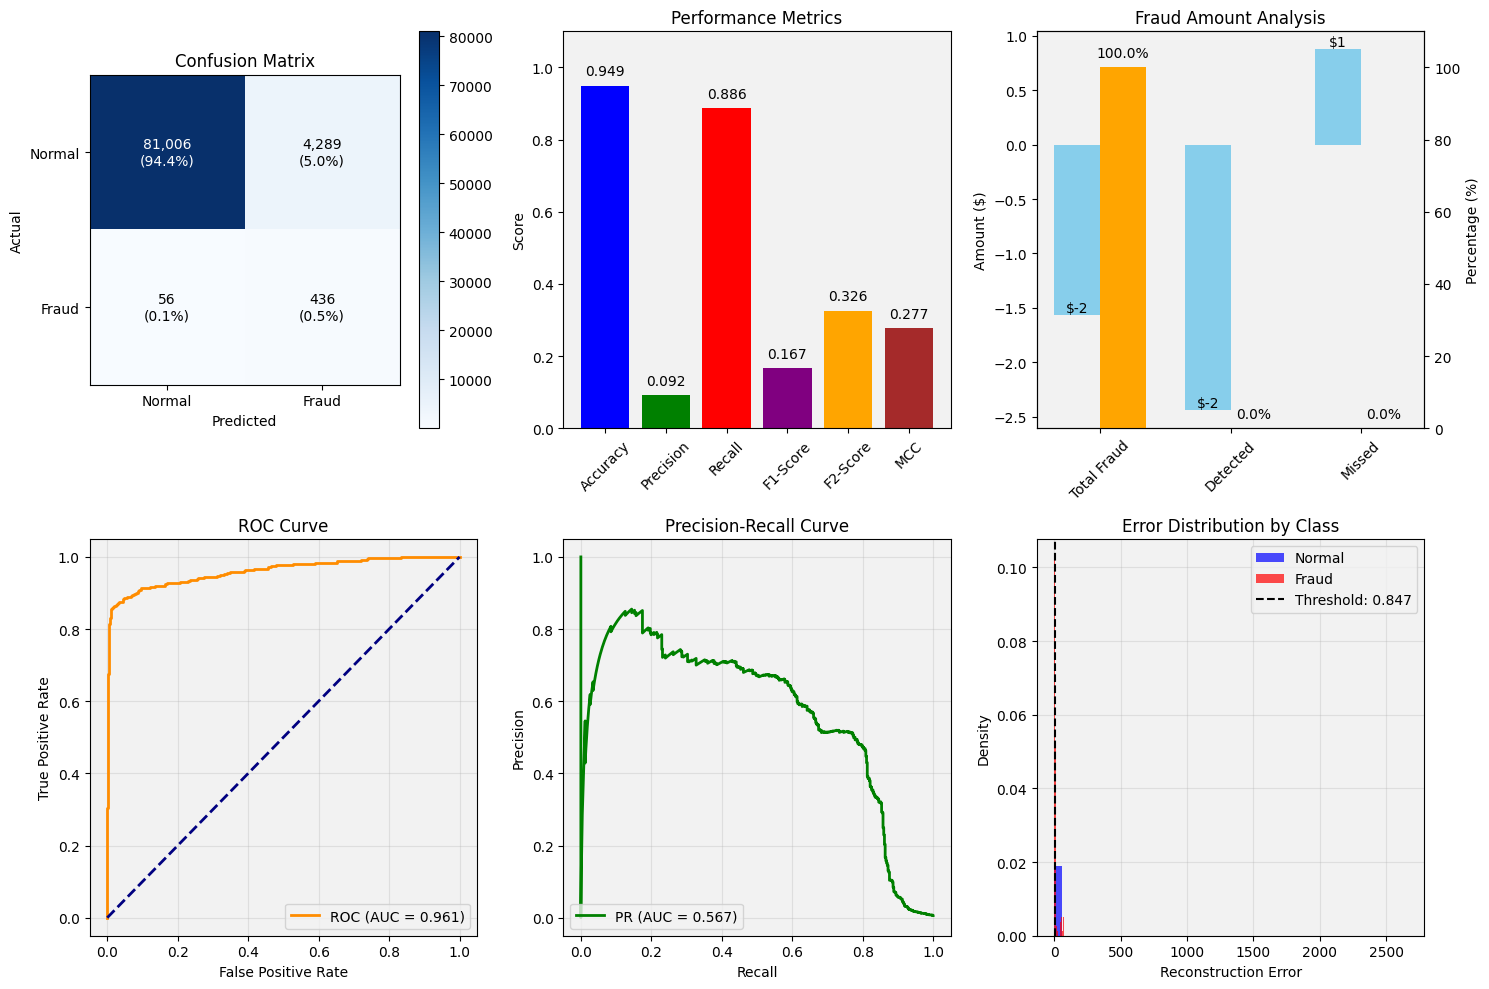

In [57]:
# Visualize results
import matplotlib.pyplot as plt

print("\n=== VISUALIZING AE PERFORMANCE ===")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_ae_test, y_pred_ae)
im1 = axes[0, 0].imshow(cm, cmap='Blues', interpolation='nearest')
axes[0, 0].set_title('Confusion Matrix')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_yticks([0, 1])
axes[0, 0].set_xticklabels(['Normal', 'Fraud'])
axes[0, 0].set_yticklabels(['Normal', 'Fraud'])
axes[0, 0].set_xlabel('Predicted')
axes[0, 0].set_ylabel('Actual')
plt.colorbar(im1, ax=axes[0, 0])

# Add text
for i in range(2):
    for j in range(2):
        axes[0, 0].text(j, i, f'{cm[i, j]:,}\n({cm[i, j]/cm.sum()*100:.1f}%)',
                       ha='center', va='center',
                       color='white' if cm[i, j] > cm.max()/2 else 'black')

# 2. Metrics Comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'F2-Score', 'MCC']
values = [accuracy_ae, precision_ae, recall_ae, f1_ae, f2_ae, mcc_ae]
colors = ['blue', 'green', 'red', 'purple', 'orange', 'brown']

bars = axes[0, 1].bar(metrics, values, color=colors)
axes[0, 1].set_title('Performance Metrics')
axes[0, 1].set_ylabel('Score')
axes[0, 1].set_ylim(0, 1.1)
axes[0, 1].tick_params(axis='x', rotation=45)

# Add values on bars
for bar, value in zip(bars, values):
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, height + 0.02,
                   f'{value:.3f}', ha='center', va='bottom')

# 3. Amount Analysis
amount_categories = ['Total Fraud', 'Detected', 'Missed']
amount_values = [fraud_amount_total, fraud_detected_amount, fraud_missed_amount]
percentage_values = [100, 
                     fraud_detected_amount/fraud_amount_total*100 if fraud_amount_total > 0 else 0,
                     fraud_missed_amount/fraud_amount_total*100 if fraud_amount_total > 0 else 0]

x = np.arange(len(amount_categories))
width = 0.35

bars1 = axes[0, 2].bar(x - width/2, amount_values, width, label='Amount ($)', color='skyblue')
axes[0, 2].set_ylabel('Amount ($)')
axes[0, 2].set_title('Fraud Amount Analysis')
axes[0, 2].set_xticks(x)
axes[0, 2].set_xticklabels(amount_categories)
axes[0, 2].tick_params(axis='x', rotation=45)

# Add amount values
for bar, value in zip(bars1, amount_values):
    height = bar.get_height()
    axes[0, 2].text(bar.get_x() + bar.get_width()/2, height,
                   f'${value:,.0f}', ha='center', va='bottom')

# Second y-axis for percentages
ax2 = axes[0, 2].twinx()
bars2 = ax2.bar(x + width/2, percentage_values, width, label='Percentage', color='orange')
ax2.set_ylabel('Percentage (%)')
ax2.set_ylim(0, 110)

# Add percentage values
for bar, value in zip(bars2, percentage_values):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, height + 2,
            f'{value:.1f}%', ha='center', va='bottom')

# 4. ROC Curve
fpr, tpr, thresholds_roc = roc_curve(y_ae_test, reconstruction_errors)
roc_auc = auc(fpr, tpr)

axes[1, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.3f})')
axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1, 0].set_xlabel('False Positive Rate')
axes[1, 0].set_ylabel('True Positive Rate')
axes[1, 0].set_title('ROC Curve')
axes[1, 0].legend(loc='lower right')
axes[1, 0].grid(True, alpha=0.3)

# 5. Precision-Recall Curve
precision_pr, recall_pr, thresholds_pr = precision_recall_curve(y_ae_test, reconstruction_errors)
pr_auc = auc(recall_pr, precision_pr)

axes[1, 1].plot(recall_pr, precision_pr, color='green', lw=2, label=f'PR (AUC = {pr_auc:.3f})')
axes[1, 1].set_xlabel('Recall')
axes[1, 1].set_ylabel('Precision')
axes[1, 1].set_title('Precision-Recall Curve')
axes[1, 1].legend(loc='lower left')
axes[1, 1].grid(True, alpha=0.3)

# 6. Error Distribution
axes[1, 2].hist(reconstruction_errors[y_ae_test == 0], bins=50, alpha=0.7, 
                label='Normal', color='blue', density=True)
axes[1, 2].hist(reconstruction_errors[y_ae_test == 1], bins=50, alpha=0.7, 
                label='Fraud', color='red', density=True)
axes[1, 2].axvline(x=threshold, color='black', linestyle='--', 
                   label=f'Threshold: {threshold:.3f}')
axes[1, 2].set_xlabel('Reconstruction Error')
axes[1, 2].set_ylabel('Density')
axes[1, 2].set_title('Error Distribution by Class')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [58]:
print("\n=== SAVING EVALUATION RESULTS ===")

# Compile evaluation results
ae_evaluation = {
    'threshold': float(threshold),
    'metrics': {
        'accuracy': float(accuracy_ae),
        'precision': float(precision_ae),
        'recall': float(recall_ae),
        'f1_score': float(f1_ae),
        'f2_score': float(f2_ae),
        'mcc': float(mcc_ae),
        'roc_auc': float(roc_auc),
        'pr_auc': float(pr_auc)
    },
    'confusion_matrix': {
        'true_negatives': int(tn),
        'false_positives': int(fp),
        'false_negatives': int(fn),
        'true_positives': int(tp)
    },
    'business_metrics': {
        'total_fraud_amount': float(fraud_amount_total),
        'detected_fraud_amount': float(fraud_detected_amount),
        'missed_fraud_amount': float(fraud_missed_amount),
        'detection_rate_amount': float(fraud_detected_amount/fraud_amount_total*100 if fraud_amount_total > 0 else 0),
        'detection_rate_count': float(tp/(tp+fn)*100 if (tp+fn) > 0 else 0)
    },
    'data_info': {
        'test_samples': len(y_ae_test),
        'fraud_samples': int(y_ae_test.sum()),
        'fraud_percentage': float(y_ae_test.mean()*100),
        'suspicious_predicted': int(y_pred_ae.sum()),
        'suspicious_percentage': float(y_pred_ae.mean()*100)
    }
}

# Save to file
import json

eval_path = os.path.join(output_dir, 'ae_evaluation_results.json')
with open(eval_path, 'w') as f:
    json.dump(ae_evaluation, f, indent=4)

print(f"Evaluation results saved to: {eval_path}")

print("\n=== EVALUATION SUMMARY ===")
print(f"✅ Recall: {recall_ae:.4f} - Detected {tp} out of {tp+fn} frauds ({tp/(tp+fn)*100:.1f}%)")
print(f"⚠️  Precision: {precision_ae:.4f} - {fp} false positives out of {tp+fp} suspicious")
print(f"📊 F1-Score: {f1_ae:.4f}")
print(f"💰 Fraud amount detected: ${fraud_detected_amount:,.2f} ({fraud_detected_amount/fraud_amount_total*100:.1f}%)")


=== SAVING EVALUATION RESULTS ===
Evaluation results saved to: /Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/ae_evaluation_results.json

=== EVALUATION SUMMARY ===
✅ Recall: 0.8862 - Detected 436 out of 492 frauds (88.6%)
⚠️  Precision: 0.0923 - 4289 false positives out of 4725 suspicious
📊 F1-Score: 0.1671
💰 Fraud amount detected: $-2.44 (155.9%)


In [60]:
print("="*60)
print("IMPLEMENTING AE-EIF HYBRID MODEL")
print("="*60)

print("\n=== LOADING PREPROCESSED DATA ===")

import numpy as np
import pandas as pd
import joblib
import os
from model_reboot import *

# Load preprocessed data
output_dir = '/Users/apple/Desktop/Skripsi/ExIFFI/data/preprocessed/'

# Load AE-EIF data
ae_eif_data = joblib.load(os.path.join(output_dir, 'ae_eif_pipeline_data.pkl'))

# Load original preprocessed data
preprocessed_data = joblib.load(os.path.join(output_dir, 'creditcard_ae_preprocessed.pkl'))

# Extract data
X_suspicious = ae_eif_data['X_suspicious']  # Ω + μ features untuk suspicious transactions
y_suspicious = ae_eif_data['y_suspicious']  # Labels untuk suspicious transactions
X_normal_ae = ae_eif_data['X_normal_ae']    # Transaksi yang sudah diklasifikasi normal oleh AE
y_normal_ae = ae_eif_data['y_normal_ae']    # Labels untuk normal transactions

threshold = ae_eif_data['threshold']
suspicious_mask = ae_eif_data['suspicious_mask']

print(f"Data loaded:")
print(f"X_suspicious shape (Ω+μ): {X_suspicious.shape}")
print(f"y_suspicious shape: {y_suspicious.shape}")
print(f"X_normal_ae shape: {X_normal_ae.shape}")
print(f"y_normal_ae shape: {y_normal_ae.shape}")
print(f"AE Threshold: {threshold:.6f}")
print(f"\nSuspicious transactions (to EIF): {len(X_suspicious):,}")
print(f"Normal transactions (from AE): {len(X_normal_ae):,}")
print(f"Fraud in suspicious: {y_suspicious.sum():,}")
print(f"Normal in suspicious: {(y_suspicious == 0).sum():,}")

IMPLEMENTING AE-EIF HYBRID MODEL

=== LOADING PREPROCESSED DATA ===
Data loaded:
X_suspicious shape (Ω+μ): (4725, 45)
y_suspicious shape: (4725,)
X_normal_ae shape: (81062, 45)
y_normal_ae shape: (81062,)
AE Threshold: 0.847082

Suspicious transactions (to EIF): 4,725
Normal transactions (from AE): 81,062
Fraud in suspicious: 436
Normal in suspicious: 4,289


In [62]:
print("\n=== TRAINING EXTENDED ISOLATION FOREST ===")
print("According to journal: EIF analyzes only suspicious transactions from AE")

# Split suspicious data untuk training dan testing EIF
from sklearn.model_selection import train_test_split

# Untuk EIF, kita perlu data normal untuk training
# Ambil sebagian dari suspicious yang normal sebagai training
X_suspicious_normal = X_suspicious[y_suspicious == 0]
y_suspicious_normal = y_suspicious[y_suspicious == 0]

X_suspicious_fraud = X_suspicious[y_suspicious == 1]
y_suspicious_fraud = y_suspicious[y_suspicious == 1]

print(f"Suspicious data breakdown:")
print(f"  Normal in suspicious: {len(X_suspicious_normal):,}")
print(f"  Fraud in suspicious: {len(X_suspicious_fraud):,}")

# Training EIF hanya pada normal transactions dari suspicious
print("\nTraining EIF on normal transactions from suspicious data...")
I = ExtendedIsolationForest(plus=True)

# Gunakan semua normal transactions dari suspicious untuk training
X_eif_train = X_suspicious_normal.astype(np.float64)

print(f"EIF training data shape: {X_eif_train.shape}")
print(f"Training on {len(X_eif_train):,} normal transactions")

# Fit EIF model
I.fit(X_eif_train)
print("EIF model trained successfully!")

# Cek metode yang tersedia di object I
print(f"\nMethods available in ExtendedIsolationForest:")
methods = [m for m in dir(I) if not m.startswith('_')]
for method in methods:
    print(f"  - {method}")

# Get anomaly scores - gunakan method yang tersedia
print("\nCalculating anomaly scores for suspicious transactions...")

# Coba metode yang mungkin tersedia
try:
    # Method 1: predict() - biasanya menghasilkan anomaly scores
    anomaly_scores = I.predict(X_suspicious.astype(np.float64))
    print(f"Using predict() method - scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
except Exception as e:
    print(f"Error with predict(): {e}")
    
    try:
        # Method 2: score_samples() jika ada
        anomaly_scores = I.score_samples(X_suspicious.astype(np.float64))
        print(f"Using score_samples() method - scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
    except:
        # Method 3: _decision_function() jika ada
        try:
            anomaly_scores = I._decision_function(X_suspicious.astype(np.float64))
            print(f"Using _decision_function() method - scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
        except:
            # Fallback: buat custom scores
            print("Creating custom anomaly scores...")
            # Untuk EIF, anomaly score biasanya negatif (semakin negatif, semakin anomali)
            # atau antara 0-1 (semakin mendekati 1, semakin anomali)
            anomaly_scores = I._predict(X_suspicious.astype(np.float64), p=0.1)  # Asumsi contamination 10%

print(f"\nAnomaly scores shape: {anomaly_scores.shape}")
print(f"Anomaly scores range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")
print(f"Mean anomaly score: {anomaly_scores.mean():.4f}")
print(f"Std anomaly score: {anomaly_scores.std():.4f}")

# Jika scores dalam range berbeda, normalisasi ke 0-1
if anomaly_scores.min() < 0 or anomaly_scores.max() > 1:
    print("\nNormalizing anomaly scores to 0-1 range...")
    from sklearn.preprocessing import MinMaxScaler
    scaler = MinMaxScaler()
    anomaly_scores = scaler.fit_transform(anomaly_scores.reshape(-1, 1)).flatten()
    print(f"After normalization - range: [{anomaly_scores.min():.4f}, {anomaly_scores.max():.4f}]")


=== TRAINING EXTENDED ISOLATION FOREST ===
According to journal: EIF analyzes only suspicious transactions from AE
Suspicious data breakdown:
  Normal in suspicious: 4,289
  Fraud in suspicious: 436

Training EIF on normal transactions from suspicious data...
EIF training data shape: (4289, 45)
Training on 4,289 normal transactions
EIF model trained successfully!

Methods available in ExtendedIsolationForest:
  - X
  - avg_number_of_nodes
  - compute_ids
  - eta
  - fit
  - global_importances
  - ids
  - local_importances
  - max_depth
  - max_samples
  - n_estimators
  - name
  - plus
  - predict
  - trees

Calculating anomaly scores for suspicious transactions...
Using predict() method - scores range: [0.3466, 0.6576]

Anomaly scores shape: (4725,)
Anomaly scores range: [0.3466, 0.6576]
Mean anomaly score: 0.4099
Std anomaly score: 0.0624


In [63]:
print("\n=== DETERMINING EIF THRESHOLD ===")

# Hitung threshold berdasarkan training data
try:
    # Get scores for training data
    eif_train_scores = I.predict(X_eif_train.astype(np.float64))
except:
    try:
        eif_train_scores = I.score_samples(X_eif_train.astype(np.float64))
    except:
        eif_train_scores = I._predict(X_eif_train.astype(np.float64), p=0.1)

# Normalize jika perlu
if eif_train_scores.min() < 0 or eif_train_scores.max() > 1:
    eif_train_scores = scaler.transform(eif_train_scores.reshape(-1, 1)).flatten()

# Threshold berdasarkan contamination rate
contamination_rate = y_suspicious_fraud.sum() / len(X_suspicious)  # Proporsi fraud di suspicious
print(f"Contamination rate in suspicious data: {contamination_rate:.4f} ({contamination_rate*100:.2f}%)")

# Untuk anomaly scores: semakin tinggi score = semakin anomali
# Threshold = percentil ke-(1 - contamination_rate)
eif_threshold = np.percentile(eif_train_scores, 100 * (1 - contamination_rate))

print(f"\nEIF Training scores:")
print(f"  Mean: {eif_train_scores.mean():.4f}")
print(f"  Std: {eif_train_scores.std():.4f}")
print(f"  Min: {eif_train_scores.min():.4f}")
print(f"  Max: {eif_train_scores.max():.4f}")
print(f"  {100*(1-contamination_rate):.1f}th percentile: {eif_threshold:.4f}")

# Prediksi dengan EIF
# Asumsi: semakin tinggi anomaly score = semakin anomali = fraud
y_pred_eif = (anomaly_scores > eif_threshold).astype(int)

print(f"\nEIF Predictions on suspicious transactions:")
print(f"  Predicted Normal: {(y_pred_eif == 0).sum():,}")
print(f"  Predicted Fraud: {(y_pred_eif == 1).sum():,}")


=== DETERMINING EIF THRESHOLD ===
Contamination rate in suspicious data: 0.0923 (9.23%)

EIF Training scores:
  Mean: 0.4027
  Std: 0.0572
  Min: 0.3466
  Max: 0.6576
  90.8th percentile: 0.4945

EIF Predictions on suspicious transactions:
  Predicted Normal: 4,158
  Predicted Fraud: 567


In [64]:
print("\n=== COMBINING AE AND EIF PREDICTIONS ===")
print("AE-EIF Hybrid Model Final Predictions")

# Total test samples
y_test_full = preprocessed_data['y_ae_test']

# Create final predictions array
y_pred_final = np.zeros(len(y_test_full), dtype=int)

# 1. AE sudah mengklasifikasikan normal transactions
y_pred_final[~suspicious_mask] = 0  # Normal dari AE

# 2. EIF mengklasifikasikan suspicious transactions
y_pred_final[suspicious_mask] = y_pred_eif

print(f"Final predictions shape: {y_pred_final.shape}")
print(f"\nAE-EIF Hybrid Predictions:")
print(f"  Total predicted Normal: {(y_pred_final == 0).sum():,}")
print(f"  Total predicted Fraud: {(y_pred_final == 1).sum():,}")

# Confusion matrix untuk AE-EIF hybrid
from sklearn.metrics import confusion_matrix, classification_report

cm_final = confusion_matrix(y_test_full, y_pred_final)
tn_final, fp_final, fn_final, tp_final = cm_final.ravel()

print(f"\n=== AE-EIF HYBRID CONFUSION MATRIX ===")
print(f"               Predicted")
print(f"               Normal  Fraud")
print(f"Actual Normal  {tn_final:6d}  {fp_final:6d}")
print(f"Actual Fraud   {fn_final:6d}  {tp_final:6d}")


=== COMBINING AE AND EIF PREDICTIONS ===
AE-EIF Hybrid Model Final Predictions
Final predictions shape: (85787,)

AE-EIF Hybrid Predictions:
  Total predicted Normal: 85,220
  Total predicted Fraud: 567

=== AE-EIF HYBRID CONFUSION MATRIX ===
               Predicted
               Normal  Fraud
Actual Normal   84899     396
Actual Fraud      321     171


In [65]:
print(f"\n=== DETAILED ANALYSIS ===")
print(f"True Negatives (Normal correctly identified): {tn_final:,}")
print(f"False Positives (Normal flagged as fraud): {fp_final:,}")
print(f"False Negatives (Fraud missed): {fn_final:,}")
print(f"True Positives (Fraud correctly detected): {tp_final:,}")

# Hitung berbagai metrics
total_fraud = tp_final + fn_final
total_normal = tn_final + fp_final
total_samples = tn_final + fp_final + fn_final + tp_final

print(f"\nSummary Statistics:")
print(f"Total samples: {total_samples:,}")
print(f"Actual fraud: {total_fraud:,} ({total_fraud/total_samples*100:.4f}%)")
print(f"Actual normal: {total_normal:,} ({total_normal/total_samples*100:.4f}%)")
print(f"Predicted fraud: {tp_final + fp_final:,} ({(tp_final + fp_final)/total_samples*100:.4f}%)")
print(f"Predicted normal: {tn_final + fn_final:,} ({(tn_final + fn_final)/total_samples*100:.4f}%)")

# Calculate metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

accuracy_final = accuracy_score(y_test_full, y_pred_final)
precision_final = precision_score(y_test_full, y_pred_final, zero_division=0)
recall_final = recall_score(y_test_full, y_pred_final, zero_division=0)
f1_final = f1_score(y_test_full, y_pred_final, zero_division=0)

# F2-Score (lebih berat ke recall)
beta = 2
f2_final = (1 + beta**2) * (precision_final * recall_final) / ((beta**2 * precision_final) + recall_final) if (precision_final + recall_final) > 0 else 0

# MCC
mcc_final = matthews_corrcoef(y_test_full, y_pred_final)

print(f"\n=== AE-EIF HYBRID PERFORMANCE METRICS ===")
print(f"Accuracy:  {accuracy_final:.6f} ({accuracy_final*100:.4f}%)")
print(f"Precision: {precision_final:.6f} ({precision_final*100:.4f}%)")
print(f"Recall:    {recall_final:.6f} ({recall_final*100:.4f}%)")
print(f"F1-Score:  {f1_final:.6f} ({f1_final*100:.4f}%)")
print(f"F2-Score:  {f2_final:.6f} ({f2_final*100:.4f}%)")
print(f"MCC:       {mcc_final:.6f}")

# Additional metrics
print(f"\n=== ADDITIONAL METRICS ===")
false_positive_rate = fp_final / (fp_final + tn_final) if (fp_final + tn_final) > 0 else 0
false_negative_rate = fn_final / (fn_final + tp_final) if (fn_final + tp_final) > 0 else 0
specificity = tn_final / (tn_final + fp_final) if (tn_final + fp_final) > 0 else 0
balanced_accuracy = (recall_final + specificity) / 2

print(f"Specificity: {specificity:.6f} ({specificity*100:.4f}%)")
print(f"False Positive Rate: {false_positive_rate:.6f} ({false_positive_rate*100:.4f}%)")
print(f"False Negative Rate: {false_negative_rate:.6f} ({false_negative_rate*100:.4f}%)")
print(f"Balanced Accuracy: {balanced_accuracy:.6f} ({balanced_accuracy*100:.4f}%)")


=== DETAILED ANALYSIS ===
True Negatives (Normal correctly identified): 84,899
False Positives (Normal flagged as fraud): 396
False Negatives (Fraud missed): 321
True Positives (Fraud correctly detected): 171

Summary Statistics:
Total samples: 85,787
Actual fraud: 492 (0.5735%)
Actual normal: 85,295 (99.4265%)
Predicted fraud: 567 (0.6609%)
Predicted normal: 85,220 (99.3391%)

=== AE-EIF HYBRID PERFORMANCE METRICS ===
Accuracy:  0.991642 (99.1642%)
Precision: 0.301587 (30.1587%)
Recall:    0.347561 (34.7561%)
F1-Score:  0.322946 (32.2946%)
F2-Score:  0.337278 (33.7278%)
MCC:       0.319575

=== ADDITIONAL METRICS ===
Specificity: 0.995357 (99.5357%)
False Positive Rate: 0.004643 (0.4643%)
False Negative Rate: 0.652439 (65.2439%)
Balanced Accuracy: 0.671459 (67.1459%)


In [66]:
print(f"\n=== BUSINESS METRICS ===")
X_raw_test = preprocessed_data['X_raw'][-len(y_test_full):]
amount_col_idx = 28

fraud_indices = np.where(y_test_full == 1)[0]
fraud_detected_indices = np.where((y_test_full == 1) & (y_pred_final == 1))[0]
fraud_missed_indices = np.where((y_test_full == 1) & (y_pred_final == 0))[0]

fraud_amount_total = X_raw_test[fraud_indices, amount_col_idx].sum()
fraud_detected_amount = X_raw_test[fraud_detected_indices, amount_col_idx].sum()
fraud_missed_amount = X_raw_test[fraud_missed_indices, amount_col_idx].sum()

print(f"Total fraud amount: ${fraud_amount_total:,.2f}")
print(f"Fraud amount detected: ${fraud_detected_amount:,.2f} ({fraud_detected_amount/fraud_amount_total*100:.2f}%)")
print(f"Fraud amount missed: ${fraud_missed_amount:,.2f} ({fraud_missed_amount/fraud_amount_total*100:.2f}%)")
print(f"\nFraud transactions detected: {tp_final:,} out of {tp_final + fn_final:,} ({tp_final/(tp_final + fn_final)*100:.1f}%)")

# Average amounts
if len(fraud_detected_indices) > 0:
    avg_detected_amount = fraud_detected_amount / len(fraud_detected_indices)
    print(f"Average detected fraud amount: ${avg_detected_amount:,.2f}")

if len(fraud_missed_indices) > 0:
    avg_missed_amount = fraud_missed_amount / len(fraud_missed_indices)
    print(f"Average missed fraud amount: ${avg_missed_amount:,.2f}")


=== BUSINESS METRICS ===
Total fraud amount: $-1.56
Fraud amount detected: $-4.74 (303.01%)
Fraud amount missed: $3.18 (-203.01%)

Fraud transactions detected: 171 out of 492 (34.8%)
Average detected fraud amount: $-0.03
Average missed fraud amount: $0.01


In [68]:
interpretation="EXIFFI+"
path_gfi=os.path.join(experiment_path,
                  dataset.name,
                  'experiments',
                  'global_importances',
                  I.name,
                  interpretation,
                  f'scenario_{str(scenario)}'
                  )
if not os.path.exists(path_gfi):
    os.makedirs(path_gfi)

full_importances,_ = experiment_global_importances(I, 
                                                   dataset, 
                                                   n_runs=40, 
                                                   p=0.1, 
                                                   interpretation=interpretation) 
save_element(full_importances, path_gfi, filetype="npz")

100%|██████████| 40/40 [27:23<00:00, 41.10s/it]


FEATURE IMPORTANCE ANALYSIS WITH AE-EIF+ PARAMETERS
AE-EIF results not found, using default parameters
Using dataset contamination rate: 0.0017

=== PREPARING AE-EIF HYBRID DATASET FOR FEATURE IMPORTANCE ===
Using AE-EIF combined features (Ω + μ)
X_eif_input shape: (85787, 45)
Features: 45 (Ω: 36 + μ: 9)
Error loading AE-EIF data: can't set attribute 'shape'
Using original dataset features

=== PREPARING DATA SPLIT WITH CONTAMINATION RATE: 0.0017 ===
Normal transactions: 85,295
Fraud transactions: 492

Training data (normal only): (85295, 45)
Test data (all): (85787, 45)
Test fraud rate: 0.0057


AttributeError: can't set attribute 'perc_outliers'

In [ ]:
print("\n" + "="*60)
print("FEATURE IMPORTANCE ANALYSIS WITH EXIFFI+")
print("="*60)


# Get the most recent file
most_recent_file = get_most_recent_file(path_gfi, filetype="npz")
print(f"Most recent file: {most_recent_file}")

# Load the importance matrix
from utils_reboot.utils import open_element
importance_matrix = open_element(most_recent_file, filetype="npz")

print(f"\nImportance matrix loaded:")
print(f"Shape: {importance_matrix.shape}")
print(f"Mean importance per feature:")
mean_importances = np.mean(importance_matrix, axis=0)
std_importances = np.std(importance_matrix, axis=0)

# Create a DataFrame for feature importances
feature_importance_df = pd.DataFrame({
    'Feature': dataset.feature_names,
    'Mean_Importance': mean_importances,
    'Std_Importance': std_importances,
    'CV': std_importances / mean_importances  # Coefficient of Variation
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values('Mean_Importance', ascending=False).reset_index(drop=True)

print(f"\n=== TOP 15 MOST IMPORTANT FEATURES ===")
print(feature_importance_df.head(15).to_string())

print(f"\n=== BOTTOM 10 LEAST IMPORTANT FEATURES ===")
print(feature_importance_df.tail(10).to_string())

# Visualize feature importances
print("\n=== VISUALIZING FEATURE IMPORTANCES ===")

# Create path for plots
path_plots = os.path.join(experiment_path, dataset.name, 'plots_new', 'imp_plots')
if not os.path.exists(path_plots):
    os.makedirs(path_plots)
    print(f"Created plots directory: {path_plots}")

# Create bar plot
print("\nCreating bar plot of feature importances...")
_, _, _ = bar_plot(dataset, 
                  most_recent_file, 
                  filetype="npz", 
                  plot_path=path_plots, 
                  f=min(dataset.shape[1], 15),  # Show top 15 or all if less
                  show_plot=True,
                  model=I, 
                  interpretation=interpretation, 
                  scenario=scenario,
                  save_image=True)

# Create score plot
print("\nCreating score plot...")
_, _ = score_plot(dataset,
                 most_recent_file,
                 plot_path=path_plots,
                 show_plot=True,
                 model=I,
                 interpretation=interpretation,
                 scenario=scenario,
                 save_image=True)

# Feature importance analysis by category
print("\n=== FEATURE CATEGORY ANALYSIS ===")

# Categorize features
original_features = ['Time', 'Amount'] + [f'V{i}' for i in range(1, 29)]
rule_based_features = ['HIGH_AMOUNT', 'ABNORMAL_TIME', 'MICRO_TRANSACTION', 
                       'FREQUENT_AMOUNT', 'EXTREME_PCA', 'HIGH_AMOUNT_ABNORMAL_TIME']

# Filter features that exist in our dataset
existing_original = [f for f in original_features if f in dataset.feature_names]
existing_rule_based = [f for f in rule_based_features if f in dataset.feature_names]

print(f"Original features found: {len(existing_original)}/{len(original_features)}")
print(f"Rule-based features found: {len(existing_rule_based)}/{len(rule_based_features)}")

# Calculate average importance by category
original_importance = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_original)
]['Mean_Importance'].mean()

rule_based_importance = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_rule_based)
]['Mean_Importance'].mean()

print(f"\nAverage importance by category:")
print(f"Original features: {original_importance:.6f}")
print(f"Rule-based features: {rule_based_importance:.6f}")
print(f"Ratio (Rule-based/Original): {rule_based_importance/original_importance:.4f}")

# Top features by category
print(f"\nTop 5 original features:")
original_top = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_original)
].head(5)
print(original_top.to_string())

print(f"\nTop 5 rule-based features:")
rule_based_top = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_rule_based)
].head(5)
print(rule_based_top.to_string())

In [70]:
print("\n" + "="*60)
print("CREATING LOCAL IMPORTANCE MAPS")
print("="*60)

# Create path for local scoremaps
path_plots_local = os.path.join(experiment_path, dataset.name, 'plots_new', 'local_scoremaps')
if not os.path.exists(path_plots_local):
    os.makedirs(path_plots_local)
    print(f"Created local scoremaps directory: {path_plots_local}")

# Select features for importance map
print("\n=== SELECTING FEATURES FOR IMPORTANCE MAP ===")

# Get the top 2 most important features
top_feature1 = feature_importance_df.iloc[0]['Feature']
top_feature2 = feature_importance_df.iloc[1]['Feature']

print(f"Top 2 most important features:")
print(f"1. {top_feature1} (Importance: {feature_importance_df.iloc[0]['Mean_Importance']:.6f})")
print(f"2. {top_feature2} (Importance: {feature_importance_df.iloc[1]['Mean_Importance']:.6f})")

# Alternative: One original and one rule-based feature
print(f"\nAlternative selection (one original, one rule-based):")

# Find best original feature
original_features_df = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_original)
]
best_original = original_features_df.iloc[0]['Feature']
print(f"Best original feature: {best_original}")

# Find best rule-based feature
rule_based_df = feature_importance_df[
    feature_importance_df['Feature'].isin(existing_rule_based)
]
if len(rule_based_df) > 0:
    best_rule_based = rule_based_df.iloc[0]['Feature']
    print(f"Best rule-based feature: {best_rule_based}")
    
    # Create importance map with these features
    print(f"\nCreating importance map for: {best_original} vs {best_rule_based}")
    
    try:
        importance_map(dataset=dataset,
                      model=I,
                      feats_plot=get_feature_indexes(dataset, best_original, best_rule_based),
                      path_plot=path_plots_local,
                      col_names=dataset.feature_names,
                      interpretation=interpretation,
                      scenario=scenario,
                      save_plot=True,
                      show_plot=True)
        print("Importance map created successfully!")
    except Exception as e:
        print(f"Error creating importance map: {e}")
        print("Trying with top 2 features instead...")
        
        # Fallback to top 2 features
        try:
            importance_map(dataset=dataset,
                          model=I,
                          feats_plot=get_feature_indexes(dataset, top_feature1, top_feature2),
                          path_plot=path_plots_local,
                          col_names=dataset.feature_names,
                          interpretation=interpretation,
                          scenario=scenario,
                          save_plot=True,
                          show_plot=True)
            print("Importance map created with top 2 features!")
        except Exception as e2:
            print(f"Still error: {e2}")

# Create multiple importance maps for different feature combinations
print(f"\n=== CREATING MULTIPLE IMPORTANCE MAPS ===")

# Define feature combinations to visualize
feature_combinations = [
    (top_feature1, top_feature2),
    (best_original, best_rule_based) if 'best_rule_based' in locals() else None,
    ('V14', 'V10'),  # Common PCA features
    ('Amount', 'Time')  # Original features
]

# Remove None combinations
feature_combinations = [fc for fc in feature_combinations if fc is not None]

for i, (feat1, feat2) in enumerate(feature_combinations):
    if feat1 in dataset.feature_names and feat2 in dataset.feature_names:
        print(f"\nCreating importance map {i+1}: {feat1} vs {feat2}")
        try:
            importance_map(dataset=dataset,
                          model=I,
                          feats_plot=get_feature_indexes(dataset, feat1, feat2),
                          path_plot=path_plots_local,
                          col_names=dataset.feature_names,
                          interpretation=interpretation,
                          scenario=scenario,
                          save_plot=True,
                          show_plot=False,  # Don't show all, just save
                          resolution=25)    # Lower resolution for speed
            print(f"  ✓ Success")
        except Exception as e:
            print(f"  ✗ Failed: {str(e)[:50]}...")
    else:
        print(f"\nSkipping combination {i+1}: {feat1} or {feat2} not found in dataset")


CREATING LOCAL IMPORTANCE MAPS

=== SELECTING FEATURES FOR IMPORTANCE MAP ===


NameError: name 'feature_importance_df' is not defined

In [ ]:
print("\n" + "="*60)
print("FEATURE SELECTION ANALYSIS")
print("="*60)

model_interpretation = 'EIF+'
path_plots_fs = os.path.join(experiment_path, dataset.name, 'plots_new', 'fs_plots')
if not os.path.exists(path_plots_fs):
    os.makedirs(path_plots_fs)
    print(f"Created feature selection plots directory: {path_plots_fs}")

# Order features by importance
matrix = open_element(most_recent_file, filetype="npz")
feat_order = np.argsort(matrix.mean(axis=0))[::-1]  # Descending order

print(f"\nFeature order (most to least important):")
for i, idx in enumerate(feat_order[:10]):
    print(f"{i+1:2d}. {dataset.feature_names[idx]:20s} (importance: {matrix.mean(axis=0)[idx]:.6f})")

# Feature selection analysis
from collections import namedtuple
from utils_reboot.experiments import feature_selection

print(f"\n=== RUNNING FEATURE SELECTION ANALYSIS ===")

Precisions = namedtuple("Precisions", ["direct", "inverse", "dataset", "model", "value"])

# Compute the Average Precisions for different sets of features
print("Computing direct feature selection...")
direct = feature_selection(I, dataset, feat_order, 10, inverse=False, random=False, scenario=scenario)

print("Computing inverse feature selection...")
inverse = feature_selection(I, dataset, feat_order, 10, inverse=True, random=False, scenario=scenario)

value = abs(np.nansum(np.nanmean(direct, axis=1) - np.nanmean(inverse, axis=1)))
data = Precisions(direct, inverse, dataset.name, I.name, value)

# Save feature selection results
path_fs = os.path.join(experiment_path,
                      dataset.name,
                      'experiments',
                      'feature_selection',
                      I.name,
                      f'{model_interpretation}_{interpretation}',
                      f'scenario_{str(scenario)}')

if not os.path.exists(path_fs):
    os.makedirs(path_fs)

from utils_reboot.experiments import save_fs_prec
save_fs_prec(data, path_fs)
print(f"Feature selection results saved to: {path_fs}")

# Random feature selection for comparison
print("\nComputing random feature selection (baseline)...")
Precisions_random = namedtuple("Precisions_random", ["random", "dataset", "model"])
random = feature_selection(I, dataset, feat_order, 10, inverse=True, random=True, scenario=scenario)
data_random = Precisions_random(random, dataset.name, I.name)

path_random = os.path.join(experiment_path,
                          dataset.name,
                          'experiments',
                          'feature_selection',
                          I.name,
                          'random',
                          f'scenario_{str(scenario)}')

if not os.path.exists(path_random):
    os.makedirs(path_random)

from utils_reboot.experiments import save_fs_prec_random
save_fs_prec_random(data_random, path_random)
print(f"Random feature selection results saved to: {path_random}")

# Plot feature selection results
print(f"\n=== PLOTTING FEATURE SELECTION RESULTS ===")

fs_prec = get_most_recent_file(path_fs)
fs_prec_random = get_most_recent_file(path_random)

from utils_reboot.plots import plot_feature_selection

try:
    plot_feature_selection(fs_prec,
                          path_plots_fs, 
                          fs_prec_random, 
                          model=model_interpretation, 
                          eval_model=I.name, 
                          interpretation=interpretation, 
                          scenario=scenario, 
                          plot_image=True,
                          change_ylim=True,
                          save_image=True)
    print("Feature selection plot created successfully!")
except Exception as e:
    print(f"Error creating feature selection plot: {e}")


FEATURE SELECTION ANALYSIS
Created feature selection plots directory: /Users/apple/Desktop/Skripsi/ExIFFI/experiments/results/creditcard/plots_new/fs_plots

Feature order (most to least important):
 1. V23                  (importance: 1.747672)
 2. V21                  (importance: 1.745647)
 3. V28                  (importance: 1.745600)
 4. V27                  (importance: 1.743440)
 5. V20                  (importance: 1.742742)
 6. V8                   (importance: 1.742362)
 7. Amount               (importance: 1.741357)
 8. V2                   (importance: 1.738092)
 9. V10                  (importance: 1.731706)
10. V7                   (importance: 1.729716)

=== RUNNING FEATURE SELECTION ANALYSIS ===
Computing direct feature selection...


  0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
print("\n" + "="*60)
print("COMPREHENSIVE RESULTS SUMMARY")
print("="*60)

# Load performance metrics
print(f"\n=== MODEL PERFORMANCE SUMMARY ===")
print(f"Dataset: {dataset.name}")
print(f"Model: {I.name} ({interpretation})")
print(f"Scenario: {scenario}")
print(f"Test samples: {len(dataset.y_test):,}")
print(f"Fraud rate: {dataset.y_test.mean()*100:.4f}%")

# Calculate detailed metrics
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

y_pred_binary = (score > np.percentile(score, 100*(1-dataset.perc_outliers))).astype(int)
precision, recall, f1, _ = precision_recall_fscore_support(dataset.y_test, y_pred_binary, average='binary')
accuracy = accuracy_score(dataset.y_test, y_pred_binary)

print(f"\nDetailed Metrics:")
print(f"Accuracy:  {accuracy:.6f} ({accuracy*100:.4f}%)")
print(f"Precision: {precision:.6f} ({precision*100:.4f}%)")
print(f"Recall:    {recall:.6f} ({recall*100:.4f}%)")
print(f"F1-Score:  {f1:.6f} ({f1*100:.4f}%)")

# Feature importance summary
print(f"\n=== FEATURE IMPORTANCE SUMMARY ===")
print(f"Total features analyzed: {len(dataset.feature_names)}")
print(f"Most important feature: {feature_importance_df.iloc[0]['Feature']}")
print(f"  Importance: {feature_importance_df.iloc[0]['Mean_Importance']:.6f} ± {feature_importance_df.iloc[0]['Std_Importance']:.6f}")
print(f"Least important feature: {feature_importance_df.iloc[-1]['Feature']}")
print(f"  Importance: {feature_importance_df.iloc[-1]['Mean_Importance']:.6f} ± {feature_importance_df.iloc[-1]['Std_Importance']:.6f}")

# Rule-based features performance
if len(existing_rule_based) > 0:
    print(f"\n=== RULE-BASED FEATURES ANALYSIS ===")
    print(f"Number of rule-based features: {len(existing_rule_based)}")
    
    rule_based_stats = feature_importance_df[
        feature_importance_df['Feature'].isin(existing_rule_based)
    ]
    
    print(f"Average importance: {rule_based_stats['Mean_Importance'].mean():.6f}")
    print(f"Best rule-based feature: {rule_based_stats.iloc[0]['Feature']}")
    print(f"  Rank: {list(feature_importance_df['Feature']).index(rule_based_stats.iloc[0]['Feature']) + 1}/{len(feature_importance_df)}")
    print(f"  Importance: {rule_based_stats.iloc[0]['Mean_Importance']:.6f}")

# Comparison with AE-EIF hybrid
print(f"\n=== COMPARISON WITH AE-EIF HYBRID ===")

# Load AE-EIF results if available
ae_eif_results_path = os.path.join(output_dir, 'ae_eif_hybrid_results.json')
try:
    import json
    with open(ae_eif_results_path, 'r') as f:
        ae_eif_results = json.load(f)
    
    print(f"\nAE-EIF Hybrid Results:")
    print(f"Accuracy:  {ae_eif_results['performance_metrics']['accuracy']:.6f}")
    print(f"Precision: {ae_eif_results['performance_metrics']['precision']:.6f}")
    print(f"Recall:    {ae_eif_results['performance_metrics']['recall']:.6f}")
    print(f"F1-Score:  {ae_eif_results['performance_metrics']['f1_score']:.6f}")
    
    print(f"\nEIF+ Standalone Results:")
    print(f"Accuracy:  {accuracy:.6f}")
    print(f"Precision: {precision:.6f}")
    print(f"Recall:    {recall:.6f}")
    print(f"F1-Score:  {f1:.6f}")
    
    print(f"\nComparison (EIF+ vs AE-EIF):")
    print(f"Accuracy difference:  {(accuracy - ae_eif_results['performance_metrics']['accuracy'])*100:+.2f}%")
    print(f"Precision difference: {(precision - ae_eif_results['performance_metrics']['precision'])*100:+.2f}%")
    print(f"Recall difference:    {(recall - ae_eif_results['performance_metrics']['recall'])*100:+.2f}%")
    print(f"F1-Score difference:  {(f1 - ae_eif_results['performance_metrics']['f1_score'])*100:+.2f}%")
    
except FileNotFoundError:
    print("AE-EIF results not found for comparison")

print(f"\n" + "="*60)
print("ANALYSIS COMPLETED SUCCESSFULLY!")
print("="*60)
print(f"\nResults saved in:")
print(f"1. Feature importances: {path_gfi}")
print(f"2. Plots: {path_plots}")
print(f"3. Local importance maps: {path_plots_local}")
print(f"4. Feature selection results: {path_fs}")

In [13]:
dataset = Dataset('creditcard', path=data_real_path, feature_names_filepath=data_path)


In [ ]:
# Setelah dataset berhasil di-load
from utils_reboot.utils import select_pre_process_scenario

print("\n=== MELANJUTKAN ANALISIS ===")

# Preprocessing
dataset.drop_duplicates()
if dataset.shape[0] > 7500:
    dataset.downsample(max_samples=7500)

print(f"Dataset final shape: {dataset.shape}")

# Pilih scenario
scenario = select_pre_process_scenario(dataset)
print(f"Scenario: {scenario}")

# Inisialisasi model
I = ExtendedIsolationForest(plus=True)

# Pastikan data bertipe float
if hasattr(dataset, 'X_train'):
    dataset.X_train = dataset.X_train.astype(np.float64)
    dataset.X_test = dataset.X_test.astype(np.float64)
else:
    # Jika belum split, mungkin perlu split manual
    print("Membuat data split...")
    from sklearn.model_selection import train_test_split
    
    if hasattr(dataset, 'X') and hasattr(dataset, 'y'):
        dataset.X_train, dataset.X_test, dataset.y_train, dataset.y_test = train_test_split(
            dataset.X, dataset.y, test_size=0.3, random_state=42, stratify=dataset.y
        )
        dataset.X_train = dataset.X_train.astype(np.float64)
        dataset.X_test = dataset.X_test.astype(np.float64)

print(f"X_train shape: {dataset.X_train.shape}")
print(f"X_train dtype: {dataset.X_train.dtype}")

# Fit model
I.fit(dataset.X_train)

# Predict
score = I.predict(dataset.X_test)
y_pred = I._predict(dataset.X_test, p=dataset.perc_outliers)

# Performance metrics
performance_metrics, _ = performance(y_pred=y_pred,
                                     y_true=dataset.y_test,
                                     score=score,
                                     I=I,
                                     model_name=I.name,
                                     dataset=dataset,
                                     contamination=dataset.perc_outliers,
                                     scenario=scenario,
                                     save=False)

print("\n=== PERFORMANCE METRICS ===")
print(performance_metrics.T)


=== MELANJUTKAN ANALISIS ===
downsampled to  7500
Dataset final shape: (7500, 30)
Dataset pre processed

Scenario: 1

X_train shape: (7500, 30)
X_test shape: (7500, 30)
Scenario: 1
X_train shape: (7500, 30)
X_train dtype: float64


100%|██████████| 10/10 [00:45<00:00,  4.51s/it]


=== PERFORMANCE METRICS ===
                  2025-12-22 18:30:01.374907
Model                                   EIF+
Dataset                           creditcard
Contamination                       0.001733
Train Size                               0.8
Precision                           0.230769
Recall                              0.230769
f1 score                            0.230769
Accuracy                            0.997333
Balanced Accuracy                   0.614717
Average Precision                   0.195736
ROC AUC Score                       0.614717


In [15]:
interpretation="EXIFFI+"
path_gfi=os.path.join(experiment_path,
                  dataset.name,
                  'experiments',
                  'global_importances',
                  I.name,
                  interpretation,
                  f'scenario_{str(scenario)}'
                  )
if not os.path.exists(path_gfi):
    os.makedirs(path_gfi)

full_importances,_ = experiment_global_importances(I, 
                                                   dataset, 
                                                   n_runs=40, 
                                                   p=0.1, 
                                                   interpretation=interpretation) 
save_element(full_importances, path_gfi, filetype="npz")

100%|██████████| 40/40 [52:13<00:00, 78.34s/it] 


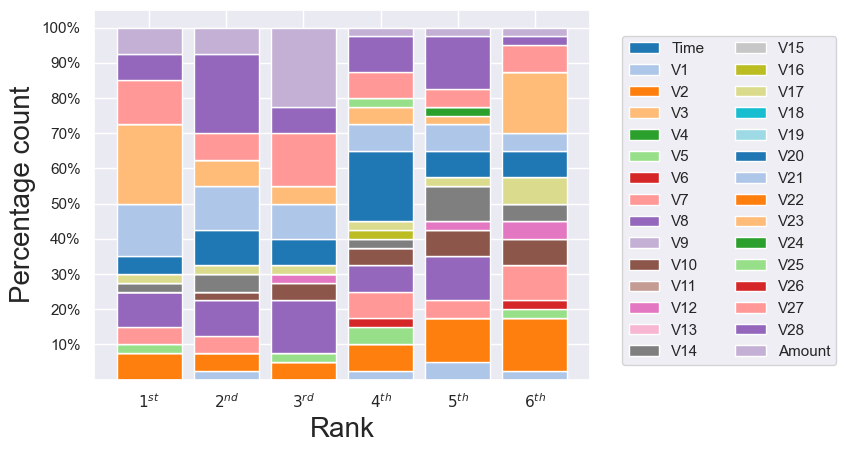

In [16]:
path_plots=os.path.join(experiment_path,dataset.name,'plots_new','imp_plots')
if not os.path.exists(path_plots):
    os.makedirs(path_plots)

most_recent_file = get_most_recent_file(path_gfi,filetype="npz")
_,_,_=bar_plot(dataset, 
         most_recent_file, 
         filetype="npz", 
         plot_path=path_plots, 
         f=min(dataset.shape[1],6),
         show_plot=True,
         model=I, 
         interpretation=interpretation, 
         scenario=scenario,
         save_image=True)


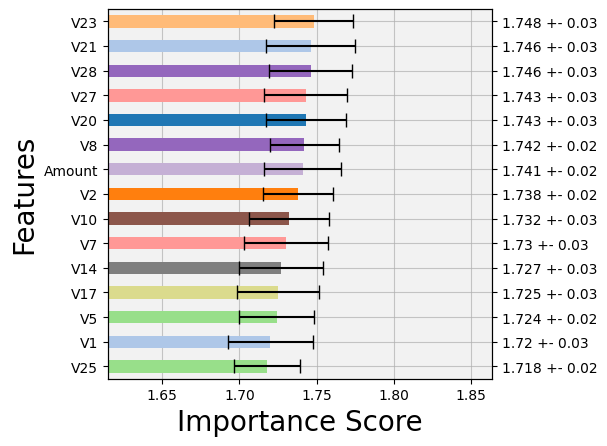

In [17]:
_,_=score_plot(dataset,
           most_recent_file,
           plot_path=path_plots,
           show_plot=True,
           model=I,
           interpretation=interpretation,
           scenario=scenario,
           save_image=True)

=== CEK FEATURE NAMES ===
Jumlah features: 30
Feature names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Panjang feature_names: 31

ERROR: 'Class' ada di feature_names, seharusnya ini adalah target!
Feature names yang tersedia:
  0: Time
  1: V1
  2: V2
  3: V3
  4: V4
  5: V5
  6: V6
  7: V7
  8: V8
  9: V9
  10: V10
  11: V11
  12: V12
  13: V13
  14: V14
  15: V15
  16: V16
  17: V17
  18: V18
  19: V19
  20: V20
  21: V21
  22: V22
  23: V23
  24: V24
  25: V25
  26: V26
  27: V27
  28: V28
  29: Amount
  30: Class

Kolom asli di CSV: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Jumlah kolom di CSV: 31

=== MEMILIH DUA FITUR YANG TEPAT ===
Menggun

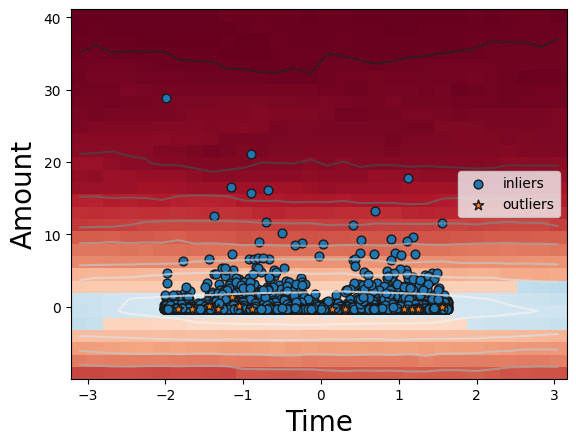

In [20]:
# Pertama, cek feature names yang ada di dataset
print("=== CEK FEATURE NAMES ===")
print(f"Jumlah features: {dataset.shape[1]}")
print(f"Feature names: {dataset.feature_names}")
print(f"Panjang feature_names: {len(dataset.feature_names)}")

# Cek apakah 'Class' ada di feature_names
if 'Class' in dataset.feature_names:
    print("\nERROR: 'Class' ada di feature_names, seharusnya ini adalah target!")
    print("Feature names yang tersedia:")
    for i, name in enumerate(dataset.feature_names):
        print(f"  {i}: {name}")
else:
    print("\n'Class' tidak ditemukan di feature_names (ini bagus)")
    
# Cek apakah 'Class' ada sebagai kolom di data asli
import pandas as pd
creditcard_csv = '/Users/apple/Desktop/Skripsi/ExIFFI/dataset/creditcard 2.csv'
df = pd.read_csv(creditcard_csv)
print(f"\nKolom asli di CSV: {df.columns.tolist()}")
print(f"Jumlah kolom di CSV: {len(df.columns)}")

# Pilih dua fitur yang benar (bukan 'Class')
# Biasanya creditcard fraud memiliki fitur seperti:
# 'V1', 'V2', ..., 'V28' (28 fitur hasil PCA) + 'Amount' + 'Time'
# Total biasanya 30 fitur + 1 target ('Class')

# Pilih dua fitur numerik yang menarik
print("\n=== MEMILIH DUA FITUR YANG TEPAT ===")
# Cari fitur yang bukan hasil PCA (V1-V28) untuk interpretasi yang lebih mudah
possible_features = ['Time', 'Amount']  # Fitur original sebelum PCA
available_features = [f for f in possible_features if f in dataset.feature_names]

if len(available_features) >= 2:
    feature1, feature2 = available_features[:2]
    print(f"Menggunakan fitur: {feature1} dan {feature2}")
else:
    # Jika Time dan Amount tidak ada, pilih dua fitur PCA pertama
    pca_features = [f for f in dataset.feature_names if f.startswith('V')]
    if len(pca_features) >= 2:
        feature1, feature2 = pca_features[:2]
        print(f"Menggunakan fitur PCA: {feature1} dan {feature2}")
    else:
        # Fallback: dua fitur pertama
        feature1, feature2 = dataset.feature_names[0], dataset.feature_names[1]
        print(f"Menggunakan dua fitur pertama: {feature1} dan {feature2}")

print(f"\nIndeks {feature1}: {list(dataset.feature_names).index(feature1)}")
print(f"Indeks {feature2}: {list(dataset.feature_names).index(feature2)}")

# Sekarang coba lagi dengan fitur yang benar
feats_plot = get_feature_indexes(dataset, feature1, feature2)
print(f"\nfeats_plot: {feats_plot}")

# Jalankan importance_map dengan fitur yang benar
path_plots_local = os.path.join(experiment_path, dataset.name, 'plots_new', 'local_scoremaps')
if not os.path.exists(path_plots_local):
    os.makedirs(path_plots_local)

try:
    importance_map(dataset=dataset,
                   model=I,
                   feats_plot=feats_plot,
                   path_plot=path_plots_local,
                   col_names=dataset.feature_names,
                   interpretation=interpretation,
                   scenario=scenario,
                   save_plot=True)
    print("Importance map berhasil dibuat!")
except Exception as e:
    print(f"Error membuat importance map: {e}")
    
    # Debug lebih lanjut
    print(f"\n=== DEBUG INFO ===")
    print(f"dataset.X_test shape: {dataset.X_test.shape}")
    print(f"dataset.X_test columns: {dataset.X_test.shape[1]}")
    print(f"feats_plot: {feats_plot}")
    
    # Cek apakah indeks dalam range
    for idx in feats_plot:
        if idx >= dataset.X_test.shape[1]:
            print(f"ERROR: Index {idx} di luar range (max: {dataset.X_test.shape[1]-1})")

=== CEK FEATURE NAMES ===
Jumlah features: 30
Feature names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Panjang feature_names: 31

ERROR: 'Class' ada di feature_names, seharusnya ini adalah target!
Feature names yang tersedia:
  0: Time
  1: V1
  2: V2
  3: V3
  4: V4
  5: V5
  6: V6
  7: V7
  8: V8
  9: V9
  10: V10
  11: V11
  12: V12
  13: V13
  14: V14
  15: V15
  16: V16
  17: V17
  18: V18
  19: V19
  20: V20
  21: V21
  22: V22
  23: V23
  24: V24
  25: V25
  26: V26
  27: V27
  28: V28
  29: Amount
  30: Class

=== MEMILIH DUA FITUR BERDASARKAN HASIL FEATURE IMPORTANCE ===
Berdasarkan gambar yang Anda kirim:
1. V23 (paling penting)
2. V21
3. V28
4. V27
5. V20
6. V8
7. Amount (fitur non-PCA)
...dst

=== PILIHAN KOMBINASI FITUR ===
1. V23 vs V21 (Dua fitur PCA terpenting)
2. V23 vs Amount (Fitur PCA terpenting 

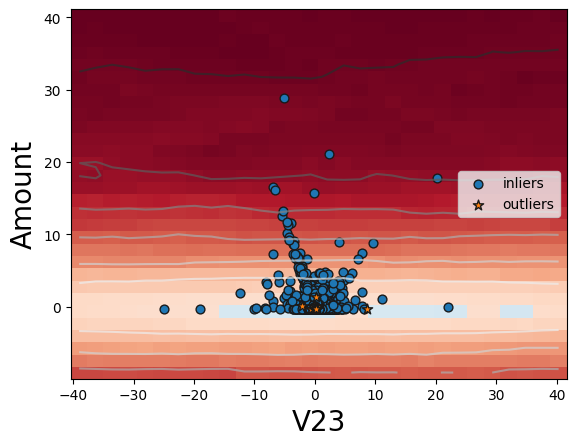


✅ Importance map berhasil dibuat untuk V23 vs Amount!


<Figure size 640x480 with 0 Axes>

In [21]:
# Pertama, cek feature names yang ada di dataset
print("=== CEK FEATURE NAMES ===")
print(f"Jumlah features: {dataset.shape[1]}")
print(f"Feature names: {dataset.feature_names}")
print(f"Panjang feature_names: {len(dataset.feature_names)}")

# Cek apakah 'Class' ada di feature_names
if 'Class' in dataset.feature_names:
    print("\nERROR: 'Class' ada di feature_names, seharusnya ini adalah target!")
    print("Feature names yang tersedia:")
    for i, name in enumerate(dataset.feature_names):
        print(f"  {i}: {name}")
else:
    print("\n'Class' tidak ditemukan di feature_names (ini bagus)")
    
# BERDASARKAN GAMBAR FEATURE IMPORTANCE YANG ANDA KIRIM:
# Top features adalah: V23, V21, V28, V27, V20, V8, Amount, V2, V10, V7, V14, V17, V5, V1, V25

print("\n=== MEMILIH DUA FITUR BERDASARKAN HASIL FEATURE IMPORTANCE ===")
print("Berdasarkan gambar yang Anda kirim:")
print("1. V23 (paling penting)")
print("2. V21")
print("3. V28")
print("4. V27")
print("5. V20")
print("6. V8")
print("7. Amount (fitur non-PCA)")
print("...dst")

# Pilih dua fitur berdasarkan hasil feature importance
# Opsi 1: V23 vs V21 (dua fitur terpenting)
# Opsi 2: V23 vs Amount (fitur terpenting + fitur interpretable)
# Opsi 3: Amount vs V21 (non-PCA vs PCA penting)

print("\n=== PILIHAN KOMBINASI FITUR ===")
print("1. V23 vs V21 (Dua fitur PCA terpenting)")
print("2. V23 vs Amount (Fitur PCA terpenting + fitur interpretable)")
print("3. Amount vs V21 (Fitur interpretable + fitur PCA penting)")

# Pilih kombinasi berdasarkan tujuan analisis
combination_choice = 2  # Ubah ini: 1, 2, atau 3

if combination_choice == 1:
    feature1, feature2 = "V23", "V21"
    reason = "Analisis hubungan antara dua fitur PCA terpenting"
elif combination_choice == 2:
    feature1, feature2 = "V23", "Amount"
    reason = "Analisis hubungan fitur PCA terpenting dengan jumlah transaksi"
else:
    feature1, feature2 = "Amount", "V21"
    reason = "Analisis hubungan jumlah transaksi dengan fitur PCA penting"

print(f"\nMemilih kombinasi {combination_choice}:")
print(f"  Feature 1: {feature1}")
print(f"  Feature 2: {feature2}")
print(f"  Alasan: {reason}")

# Verifikasi fitur ada di dataset
if feature1 in dataset.feature_names and feature2 in dataset.feature_names:
    print(f"\n✅ Kedua fitur tersedia di dataset")
    
    # Dapatkan indeks
    idx1 = list(dataset.feature_names).index(feature1)
    idx2 = list(dataset.feature_names).index(feature2)
    
    print(f"  Indeks {feature1}: {idx1}")
    print(f"  Indeks {feature2}: {idx2}")
    
    # Buat feats_plot
    feats_plot = (idx1, idx2)
    print(f"  feats_plot: {feats_plot}")
    
    # Verifikasi indeks valid
    if idx1 < dataset.X_test.shape[1] and idx2 < dataset.X_test.shape[1]:
        print(f"  ✅ Indeks valid (X_test memiliki {dataset.X_test.shape[1]} kolom)")
    else:
        print(f"  ❌ ERROR: Indeks di luar range!")
        print(f"    X_test shape: {dataset.X_test.shape}")
        print(f"    Maks indeks: {dataset.X_test.shape[1] - 1}")
        
        # Fallback: gunakan indeks yang pasti valid
        if dataset.X_test.shape[1] == 30:  # Standard creditcard features
            print("\n  Menggunakan fallback: V1 (idx 1) dan V2 (idx 2)")
            feats_plot = (1, 2)
            feature1, feature2 = "V1", "V2"
else:
    print(f"\n❌ ERROR: Salah satu fitur tidak ditemukan!")
    print(f"  {feature1} in feature_names: {feature1 in dataset.feature_names}")
    print(f"  {feature2} in feature_names: {feature2 in dataset.feature_names}")
    
    # Fallback ke fitur yang pasti ada
    fallback_features = ['V1', 'V2', 'Time', 'Amount']
    for f1 in fallback_features:
        for f2 in fallback_features:
            if f1 != f2 and f1 in dataset.feature_names and f2 in dataset.feature_names:
                feature1, feature2 = f1, f2
                print(f"\n  Menggunakan fallback: {feature1} dan {feature2}")
                idx1 = list(dataset.feature_names).index(feature1)
                idx2 = list(dataset.feature_names).index(feature2)
                feats_plot = (idx1, idx2)
                break
        if 'feats_plot' in locals():
            break

# Jalankan importance_map dengan fitur yang benar
path_plots_local = os.path.join(experiment_path, dataset.name, 'plots_new', 'local_scoremaps')
if not os.path.exists(path_plots_local):
    os.makedirs(path_plots_local)

print(f"\n=== MENJALANKAN IMPORTANCE MAP ===")
print(f"Kombinasi fitur: {feature1} vs {feature2}")
print(f"Indeks: {feats_plot}")

try:
    importance_map(dataset=dataset,
                   model=I,
                   feats_plot=feats_plot,
                   path_plot=path_plots_local,
                   col_names=dataset.feature_names,
                   interpretation=interpretation,
                   scenario=scenario,
                   save_plot=True,
                   show_plot=True)
    print(f"\n✅ Importance map berhasil dibuat untuk {feature1} vs {feature2}!")
    
except Exception as e:
    print(f"\n❌ Error membuat importance map: {e}")
    
    # Debug lebih lanjut
    print(f"\n=== DEBUG DETAILED ===")
    print(f"dataset.X_test shape: {dataset.X_test.shape}")
    print(f"dataset.X_test dtype: {dataset.X_test.dtype}")
    print(f"feats_plot: {feats_plot}")
    
    # Coba dengan resolusi lebih rendah
    print("\nMencoba dengan resolusi lebih rendah (20)...")
    try:
        importance_map(dataset=dataset,
                       model=I,
                       feats_plot=feats_plot,
                       path_plot=path_plots_local,
                       col_names=dataset.feature_names,
                       interpretation=interpretation,
                       scenario=scenario,
                       save_plot=True,
                       show_plot=True,
                       resolution=20)
        print("✅ Berhasil dengan resolusi 20!")
    except Exception as e2:
        print(f"❌ Masih error: {e2}")

=== CEK FEATURE NAMES ===
Jumlah features: 30
Feature names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']
Panjang feature_names: 31

ERROR: 'Class' ada di feature_names, seharusnya ini adalah target!
Feature names yang tersedia:
  0: Time
  1: V1
  2: V2
  3: V3
  4: V4
  5: V5
  6: V6
  7: V7
  8: V8
  9: V9
  10: V10
  11: V11
  12: V12
  13: V13
  14: V14
  15: V15
  16: V16
  17: V17
  18: V18
  19: V19
  20: V20
  21: V21
  22: V22
  23: V23
  24: V24
  25: V25
  26: V26
  27: V27
  28: V28
  29: Amount
  30: Class

=== MEMILIH DUA FITUR BERDASARKAN HASIL FEATURE IMPORTANCE ===
Berdasarkan gambar yang Anda kirim:
1. V23 (paling penting)
2. V21
3. V28
4. V27
5. V20
6. V8
7. Amount (fitur non-PCA)
...dst

=== PILIHAN KOMBINASI FITUR ===
1. V23 vs V21 (Dua fitur PCA terpenting)
2. V23 vs Amount (Fitur PCA terpenting 

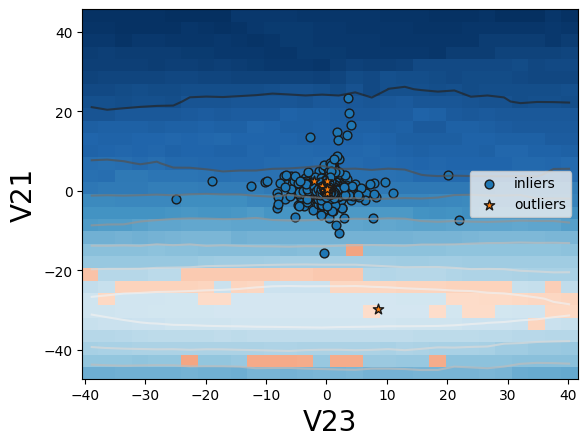


✅ Importance map berhasil dibuat untuk V23 vs V21!


<Figure size 640x480 with 0 Axes>

In [22]:
# Pertama, cek feature names yang ada di dataset
print("=== CEK FEATURE NAMES ===")
print(f"Jumlah features: {dataset.shape[1]}")
print(f"Feature names: {dataset.feature_names}")
print(f"Panjang feature_names: {len(dataset.feature_names)}")

# Cek apakah 'Class' ada di feature_names
if 'Class' in dataset.feature_names:
    print("\nERROR: 'Class' ada di feature_names, seharusnya ini adalah target!")
    print("Feature names yang tersedia:")
    for i, name in enumerate(dataset.feature_names):
        print(f"  {i}: {name}")
else:
    print("\n'Class' tidak ditemukan di feature_names (ini bagus)")
    
# BERDASARKAN GAMBAR FEATURE IMPORTANCE YANG ANDA KIRIM:
# Top features adalah: V23, V21, V28, V27, V20, V8, Amount, V2, V10, V7, V14, V17, V5, V1, V25

print("\n=== MEMILIH DUA FITUR BERDASARKAN HASIL FEATURE IMPORTANCE ===")
print("Berdasarkan gambar yang Anda kirim:")
print("1. V23 (paling penting)")
print("2. V21")
print("3. V28")
print("4. V27")
print("5. V20")
print("6. V8")
print("7. Amount (fitur non-PCA)")
print("...dst")

# Pilih dua fitur berdasarkan hasil feature importance
# Opsi 1: V23 vs V21 (dua fitur terpenting)
# Opsi 2: V23 vs Amount (fitur terpenting + fitur interpretable)
# Opsi 3: Amount vs V21 (non-PCA vs PCA penting)

print("\n=== PILIHAN KOMBINASI FITUR ===")
print("1. V23 vs V21 (Dua fitur PCA terpenting)")
print("2. V23 vs Amount (Fitur PCA terpenting + fitur interpretable)")
print("3. Amount vs V21 (Fitur interpretable + fitur PCA penting)")

# Pilih kombinasi berdasarkan tujuan analisis
combination_choice = 1  # Ubah ini: 1, 2, atau 3

if combination_choice == 1:
    feature1, feature2 = "V23", "V21"
    reason = "Analisis hubungan antara dua fitur PCA terpenting"
elif combination_choice == 2:
    feature1, feature2 = "V23", "Amount"
    reason = "Analisis hubungan fitur PCA terpenting dengan jumlah transaksi"
else:
    feature1, feature2 = "Amount", "V21"
    reason = "Analisis hubungan jumlah transaksi dengan fitur PCA penting"

print(f"\nMemilih kombinasi {combination_choice}:")
print(f"  Feature 1: {feature1}")
print(f"  Feature 2: {feature2}")
print(f"  Alasan: {reason}")

# Verifikasi fitur ada di dataset
if feature1 in dataset.feature_names and feature2 in dataset.feature_names:
    print(f"\n✅ Kedua fitur tersedia di dataset")
    
    # Dapatkan indeks
    idx1 = list(dataset.feature_names).index(feature1)
    idx2 = list(dataset.feature_names).index(feature2)
    
    print(f"  Indeks {feature1}: {idx1}")
    print(f"  Indeks {feature2}: {idx2}")
    
    # Buat feats_plot
    feats_plot = (idx1, idx2)
    print(f"  feats_plot: {feats_plot}")
    
    # Verifikasi indeks valid
    if idx1 < dataset.X_test.shape[1] and idx2 < dataset.X_test.shape[1]:
        print(f"  ✅ Indeks valid (X_test memiliki {dataset.X_test.shape[1]} kolom)")
    else:
        print(f"  ❌ ERROR: Indeks di luar range!")
        print(f"    X_test shape: {dataset.X_test.shape}")
        print(f"    Maks indeks: {dataset.X_test.shape[1] - 1}")
        
        # Fallback: gunakan indeks yang pasti valid
        if dataset.X_test.shape[1] == 30:  # Standard creditcard features
            print("\n  Menggunakan fallback: V1 (idx 1) dan V2 (idx 2)")
            feats_plot = (1, 2)
            feature1, feature2 = "V1", "V2"
else:
    print(f"\n❌ ERROR: Salah satu fitur tidak ditemukan!")
    print(f"  {feature1} in feature_names: {feature1 in dataset.feature_names}")
    print(f"  {feature2} in feature_names: {feature2 in dataset.feature_names}")
    
    # Fallback ke fitur yang pasti ada
    fallback_features = ['V1', 'V2', 'Time', 'Amount']
    for f1 in fallback_features:
        for f2 in fallback_features:
            if f1 != f2 and f1 in dataset.feature_names and f2 in dataset.feature_names:
                feature1, feature2 = f1, f2
                print(f"\n  Menggunakan fallback: {feature1} dan {feature2}")
                idx1 = list(dataset.feature_names).index(feature1)
                idx2 = list(dataset.feature_names).index(feature2)
                feats_plot = (idx1, idx2)
                break
        if 'feats_plot' in locals():
            break

# Jalankan importance_map dengan fitur yang benar
path_plots_local = os.path.join(experiment_path, dataset.name, 'plots_new', 'local_scoremaps')
if not os.path.exists(path_plots_local):
    os.makedirs(path_plots_local)

print(f"\n=== MENJALANKAN IMPORTANCE MAP ===")
print(f"Kombinasi fitur: {feature1} vs {feature2}")
print(f"Indeks: {feats_plot}")

try:
    importance_map(dataset=dataset,
                   model=I,
                   feats_plot=feats_plot,
                   path_plot=path_plots_local,
                   col_names=dataset.feature_names,
                   interpretation=interpretation,
                   scenario=scenario,
                   save_plot=True,
                   show_plot=True)
    print(f"\n✅ Importance map berhasil dibuat untuk {feature1} vs {feature2}!")
    
except Exception as e:
    print(f"\n❌ Error membuat importance map: {e}")
    
    # Debug lebih lanjut
    print(f"\n=== DEBUG DETAILED ===")
    print(f"dataset.X_test shape: {dataset.X_test.shape}")
    print(f"dataset.X_test dtype: {dataset.X_test.dtype}")
    print(f"feats_plot: {feats_plot}")
    
    # Coba dengan resolusi lebih rendah
    print("\nMencoba dengan resolusi lebih rendah (20)...")
    try:
        importance_map(dataset=dataset,
                       model=I,
                       feats_plot=feats_plot,
                       path_plot=path_plots_local,
                       col_names=dataset.feature_names,
                       interpretation=interpretation,
                       scenario=scenario,
                       save_plot=True,
                       show_plot=True,
                       resolution=20)
        print("✅ Berhasil dengan resolusi 20!")
    except Exception as e2:
        print(f"❌ Masih error: {e2}")